# Diabetes Onset Prediction Using Machine Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/blob/main/notebooks/Diabetes_Onset_Prediction.ipynb)

| | |
|---|---|
| **Student** | Hardik Jain |
| **Student ID** | 23070521056 |
| **Course** | Predictive Analytics |
| **Dataset 1** | Pima Indians Diabetes Dataset (768 patients, 8 diagnostic measurements) |
| **Dataset 2** | Early Stage Diabetes Risk Prediction Dataset, UCI (520 questionnaire records, 16 symptom/demographic features) |

**Project objective.** Build end-to-end predictive analytics models that estimate whether a person is likely to have diabetes, and show how such models could *support early screening* by flagging higher-risk individuals for follow-up testing. The main pipeline is built on the Pima dataset (clinical measurements); a second, independent dataset (self-reported symptoms) is analysed with the same evaluation philosophy so that the results can be compared.

> **Disclaimer.** This notebook is an academic machine-learning exercise. The models are **not** medical diagnostic tools and must not be used to make clinical decisions.

### How this notebook is organised

| # | Section | # | Section |
|---|---|---|---|
| 0 | Environment setup and imports | 10 | Preprocessing – Dataset 1 |
| 1 | Project Introduction (incl. KDD workflow) | 11 | Preprocessing – Dataset 2 |
| 2 | Problem Statement | 12 | Predictive Modelling – Dataset 1 |
| 3 | Objectives | 13 | Predictive Modelling – Dataset 2 |
| 4 | Dataset 1 – Pima Indians Diabetes | 14 | Model Evaluation |
| 5 | Dataset 2 – Early Stage Diabetes Risk Prediction | 15 | Comparison of Results |
| 6 | Data Understanding | 16 | Feature Importance / SHAP Interpretation |
| 7 | EDA – Dataset 1 | 17 | Overall Findings |
| 8 | EDA – Dataset 2 | 18 | Conclusion |
| 9 | Data Quality / Missing Values | 19 | Limitations |
| | | 20 | References |

**Naming convention used in the code.** Variables of **Dataset 1 (Pima)** keep their original names (`df_raw`, `df`, `X_train`, `models`, `results`, ...). Every variable of **Dataset 2** starts with **`es_`** (for *early stage*: `es_raw`, `es_X_train`, `es_models`, `es_results`, ...), so the two pipelines can never overwrite each other.

## 0. Environment Setup (Local or Google Colab)

This notebook runs both **locally** (inside the cloned project folder) and in **Google Colab** (click the *Open in Colab* badge above, then **Runtime → Run all**).

The cell below:

1. checks whether the notebook is running inside the project folder;
2. if not (for example in Colab, where only this `.ipynb` file is opened), **clones the project from GitHub** so that the helper modules in `src/` are available;
3. installs any missing libraries (Colab already includes most of them).

The datasets are then loaded in Sections 4 and 5: in Colab, Dataset 1 is read **directly from the GitHub repository** and Dataset 2 is downloaded from the **UCI repository** (with the copy in the GitHub repository as a fallback).

> **If an installation fails** (e.g. no internet), run `%pip install -r requirements.txt` in a new cell, restart the kernel and run all cells again. XGBoost is optional: if it is missing, the notebook skips that model instead of crashing; SHAP falls back to permutation importance.

In [1]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

# The repository can be overridden (e.g. for a fork) with the DIABETES_REPO_URL environment variable
GITHUB_REPO_URL = os.environ.get("DIABETES_REPO_URL", "https://github.com/hardikjain2005/"
                                 "-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning.git")
IN_COLAB = "google.colab" in sys.modules


def inside_project():
    return any((p / "src" / "preprocessing.py").exists() for p in [Path.cwd(), *Path.cwd().parents])


if not inside_project():
    # e.g. Google Colab: fetch the project (src/ modules, data/) from GitHub
    clone_dir = Path("/content/diabetes-onset-prediction") if IN_COLAB else Path.cwd() / "diabetes-onset-prediction"
    if not (clone_dir / "src" / "preprocessing.py").exists():
        print("Cloning project from GitHub ...")
        subprocess.run(["git", "clone", "--depth", "1", GITHUB_REPO_URL, str(clone_dir)], check=True)
    os.chdir(clone_dir)

# install any libraries that are not available yet (Colab already has most of them)
required = {"imblearn": "imbalanced-learn", "xgboost": "xgboost", "shap": "shap", "seaborn": "seaborn"}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

print("Running in Google Colab:", IN_COLAB)
print("Working directory      :", Path.cwd().name)

Running in Google Colab: False
Working directory      : notebooks


### 0.1 Import Libraries and Configuration

* **pandas / numpy** – data handling
* **matplotlib / seaborn** – visualisation
* **scikit-learn** – splitting, imputation, scaling, models and metrics
* **imbalanced-learn** – SMOTE and an imbalance-aware pipeline
* **xgboost** – gradient-boosted trees (optional: skipped gracefully if not installed)
* **shap** – model interpretation

The project's reusable helper functions live in `src/`: `preprocessing.py` and `models.py` (Dataset 1), `early_stage.py` (Dataset 2) and `evaluation.py` (both). The cell below locates the project root so the notebook works whether it is started from the project folder or from `notebooks/`. All file paths are **relative to the project folder** (`data/`, `results/`); nothing depends on a particular computer. The `data/` folders are created if they do not exist. A single `RANDOM_STATE = 42` is used everywhere for reproducibility.

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
import sklearn
import imblearn

try:
    import xgboost
    XGB_VERSION = xgboost.__version__
except ImportError:
    XGB_VERSION = "not installed (XGBoost models are skipped)"

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- locate the project root (folder that contains src/preprocessing.py) ----
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "preprocessing.py").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from inside the diabetes-onset-prediction project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import (FEATURES, TARGET, COLUMNS, ZERO_AS_MISSING, RANDOM_STATE,
                           load_data, GITHUB_DATA_URL, count_invalid_zeros, replace_invalid_zeros,
                           split_data, build_preprocessor)
from models import get_classifiers, build_pipeline, get_models, train_models, cross_validate_models
from evaluation import (evaluate_models, print_classification_reports, plot_confusion_matrices,
                        plot_roc_curves, best_per_metric)
from early_stage import (ES_FILENAME, UCI_ZIP_URL, download_early_stage, load_early_stage,
                         find_target_column, encode_target, clean_categories, feature_types,
                         missing_value_table, build_es_preprocessor, clean_feature_names, get_es_models)

DATA_DIR = PROJECT_ROOT / "data"                  # i.e. ./data relative to the project folder
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "pima-indians-diabetes.csv"   # Dataset 1
ES_PATH = DATA_DIR / ES_FILENAME                  # Dataset 2
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- plotting configuration ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.labelsize": 11,
                     "axes.titleweight": "bold"})
OUTCOME_LABELS = {0: "No Diabetes", 1: "Diabetes"}
PALETTE = {"No Diabetes": "#4C72B0", "Diabetes": "#DD8452"}
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def save_fig(fig, name):
    """Save a figure to results/figures/ at a readable resolution."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


print("Project root :", PROJECT_ROOT.name)
print("Random state :", RANDOM_STATE)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"imbalanced-learn {imblearn.__version__} | xgboost {XGB_VERSION}")

Project root : diabetes-onset-prediction
Random state : 42
pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | xgboost 3.4.1


## 1. Project Introduction

**What is diabetes?** Diabetes mellitus is a chronic metabolic condition in which the body cannot properly regulate blood glucose, either because it produces too little insulin or because its cells respond poorly to insulin. Persistently high blood glucose can, over time, damage the heart, kidneys, eyes and nerves.

**Why early screening matters.** Type 2 diabetes often develops gradually and can remain unnoticed for years. Identifying people at higher risk early allows confirmatory testing, lifestyle changes and timely medical care, which can reduce the risk of complications.

**Why predictive analytics?** Health services routinely collect information such as plasma glucose and BMI, or symptoms reported by patients. A predictive model can learn patterns linking this information to a known outcome and then produce a *risk estimate* for new people. Such an estimate can help prioritise who should be referred for proper clinical testing.

**Why two datasets?** The first dataset (Pima) describes patients through **clinical measurements**; the second (Early Stage Diabetes Risk Prediction) describes them through **symptoms and demographics** collected by questionnaire. Analysing both with the same evaluation philosophy shows how much the kind of information available changes what a model can achieve. The datasets have **different features and populations, so they are not merged**: each is modelled separately and only the *results* are compared.

### 1.1 KDD / Predictive Analytics Workflow

The project follows the **Knowledge Discovery in Databases (KDD)** process, adapted to predictive modelling, for each dataset:

**Problem Definition → Data Selection → Data Understanding → Data Cleaning → Data Transformation → Exploratory Data Analysis → Model Construction → Model Evaluation → Interpretation → Knowledge / Insights**

The diagram below summarises the flow.

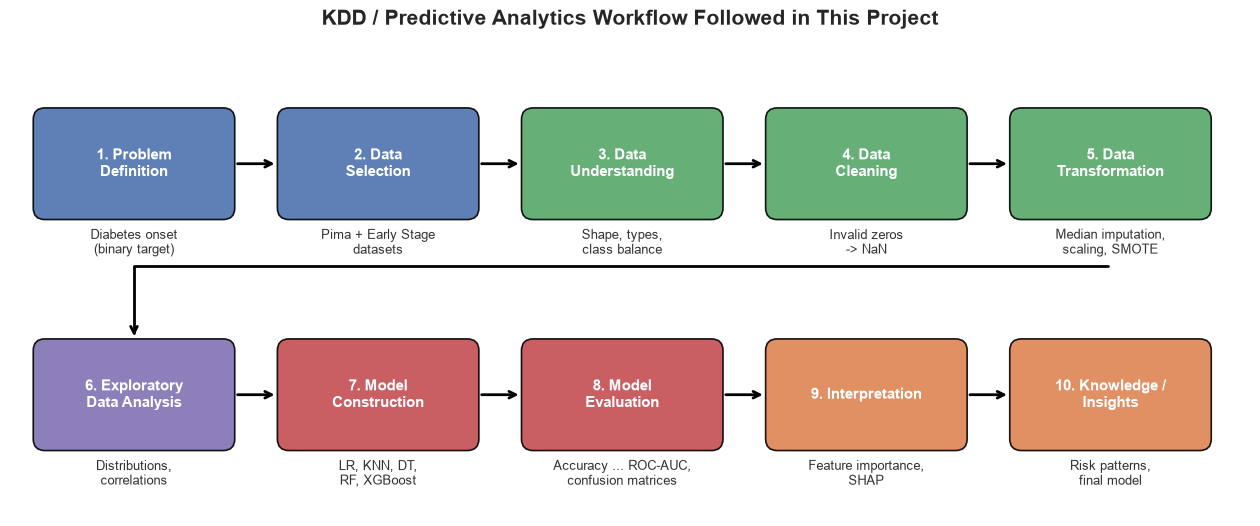

In [3]:
stages = ["Problem\nDefinition", "Data\nSelection", "Data\nUnderstanding", "Data\nCleaning",
          "Data\nTransformation", "Exploratory\nData Analysis", "Model\nConstruction",
          "Model\nEvaluation", "Interpretation", "Knowledge /\nInsights"]
details = ["Diabetes onset\n(binary target)", "Pima + Early Stage\ndatasets", "Shape, types,\nclass balance",
           "Invalid zeros\n-> NaN", "Median imputation,\nscaling, SMOTE", "Distributions,\ncorrelations",
           "LR, KNN, DT,\nRF, XGBoost", "Accuracy ... ROC-AUC,\nconfusion matrices",
           "Feature importance,\nSHAP", "Risk patterns,\nfinal model"]
colors = ["#4C72B0"] * 2 + ["#55A868"] * 3 + ["#8172B3"] + ["#C44E52"] * 2 + ["#DD8452"] * 2

fig, ax = plt.subplots(figsize=(16, 6.2))
ax.set_xlim(0, 16); ax.set_ylim(0, 6.2); ax.axis("off")
w, h = 2.5, 1.35
xs = [0.35 + i * 3.15 for i in range(5)]
positions = [(x, 3.9) for x in xs] + [(x, 0.9) for x in xs]
for i, ((x, y), stage, detail, c) in enumerate(zip(positions, stages, details, colors)):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                facecolor=c, edgecolor="black", linewidth=1.2, alpha=0.9))
    ax.text(x + w / 2, y + h / 2, f"{i + 1}. {stage}", ha="center", va="center",
            color="white", fontsize=11, fontweight="bold")
    ax.text(x + w / 2, y - 0.35, detail, ha="center", va="center", fontsize=9, color="#333333")
    if i in (0, 1, 2, 3, 5, 6, 7, 8):
        nx, ny = positions[i + 1]
        ax.annotate("", xy=(nx - 0.05, ny + h / 2), xytext=(x + w + 0.05, y + h / 2),
                    arrowprops=dict(arrowstyle="->", lw=2, color="black"))
# connector from stage 5 (end of row 1) to stage 6 (start of row 2)
x5, y5 = positions[4]; x6, y6 = positions[5]
ax.annotate("", xy=(x6 + w / 2, y6 + h + 0.05),
            xytext=(x5 + w / 2, y5 - 0.65),
            arrowprops=dict(arrowstyle="->", lw=2, color="black",
                            connectionstyle="angle,angleA=180,angleB=90,rad=0"))
ax.set_title("KDD / Predictive Analytics Workflow Followed in This Project", fontsize=15, pad=10)
save_fig(fig, "01_kdd_workflow.png")
plt.show()

## 2. Problem Statement

**Prediction task.** For each dataset this is a **supervised binary classification** problem.

| | Dataset 1 – Pima | Dataset 2 – Early Stage |
|---|---|---|
| **Input features (X)** | Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age | Age, Gender and 14 Yes/No symptoms (Polyuria, Polydipsia, sudden weight loss, weakness, Polyphagia, Genital thrush, visual blurring, Itching, Irritability, delayed healing, partial paresis, muscle stiffness, Alopecia, Obesity) |
| **Target (y)** | Outcome (0 = no diabetes, 1 = diabetes) | class (Negative = 0, Positive = 1) |
| **Type of information** | Laboratory / clinical measurements | Self-reported symptoms and demographics |

**Formal statement.** Given a vector of features $X$ for a person, learn a function $f$ such that $f(X) \rightarrow \hat{y} \in \{0, 1\}$, together with an estimated probability $P(y = 1 \mid X)$, separately for each dataset.

The models produced here are **academic predictive screening models**. They identify statistical associations in specific historical datasets; they do not diagnose disease.

## 3. Objectives

1. **Understand and clean both datasets**, including hidden data-quality problems (invalid zeros in Dataset 1, duplicate records in Dataset 2).
2. **Explore** how each feature relates to diabetes in each dataset.
3. Build **leak-free preprocessing pipelines** in which every step that learns from data is fitted on the training split only.
4. **Compare five classifiers** (Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, XGBoost) on each dataset using Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrices and cross-validation.
5. **Select a final model per dataset** with the same transparent, recall-aware rule.
6. **Explain the models** with feature importance and SHAP.
7. **Compare the two datasets**: which is easier to predict, which features matter, and whether models behave consistently.

## 4. Dataset 1 – Pima Indians Diabetes (Data Selection)

The dataset is the **Pima Indians Diabetes Dataset**, originally from the US National Institute of Diabetes and Digestive and Kidney Diseases and distributed through the UCI Machine Learning Repository. All patients are females of Pima Indian heritage aged at least 21 years.

The dataset (originally from `https://github.com/jbrownlee/Datasets`, stored with column headers) is part of this project's GitHub repository:

`https://raw.githubusercontent.com/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/main/data/pima-indians-diabetes.csv`

* In **Google Colab** (or whenever the local file is missing) it is **read directly from this GitHub URL**.
* When running locally inside the project, the identical copy in `data/pima-indians-diabetes.csv` is used.

Here we load Dataset 1 and look at the first and last rows.

In [4]:
if IN_COLAB or not DATA_PATH.exists():
    try:
        df_raw = load_data(GITHUB_DATA_URL)          # read directly from GitHub
        DATA_SOURCE = "GitHub - " + GITHUB_DATA_URL
    except Exception as exc:
        raise ConnectionError(
            f"Could not read the dataset from GitHub ({exc}).\n"
            "Check the internet connection, or place the CSV at data/pima-indians-diabetes.csv."
        )
else:
    df_raw = load_data(DATA_PATH)                    # local copy inside the project
    DATA_SOURCE = "local file - " + str(DATA_PATH.relative_to(PROJECT_ROOT))

print("Loaded from:", DATA_SOURCE)
print("Shape :", df_raw.shape, "(rows, columns)")
print("Columns:", list(df_raw.columns))

Loaded from: local file - data/pima-indians-diabetes.csv
Shape : (768, 9) (rows, columns)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [5]:
print("First 5 rows")
df_raw.head()

First 5 rows


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
print("Last 5 rows")
df_raw.tail()

Last 5 rows


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


## 5. Dataset 2 – Early Stage Diabetes Risk Prediction (Data Selection)

**Source.** UCI Machine Learning Repository, dataset 529 (donated 2020), DOI [10.24432/C5VG8H](https://doi.org/10.24432/C5VG8H), licensed **CC BY 4.0** (free to share and adapt with attribution). The data were collected through direct questionnaires from patients of **Sylhet Diabetes Hospital, Bangladesh**, and approved by a doctor. The dataset was introduced by Islam et al. (2019).

**Content.** 520 records with `Age` (numeric), `Gender` (Male/Female), 14 **Yes/No symptoms** and a `class` label (Positive/Negative).

**How it is loaded (no manual step needed).**

1. If `data/early_stage_diabetes_risk_prediction.csv` already exists, it is used.
2. Otherwise the official **UCI zip file is downloaded automatically** and the CSV is saved to `data/`.
3. If UCI cannot be reached, the copy stored in this project's **GitHub repository** is used.

> **Manual fallback.** If you have no internet access, download the zip from <https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset>, extract `diabetes_data_upload.csv`, rename it to `early_stage_diabetes_risk_prediction.csv` and place it in the project's `data/` folder.

We do **not** assume that this dataset has the same columns as Pima: its columns are inspected in Section 6.2 before any preprocessing code is written.

In [7]:
if ES_PATH.exists():
    es_raw = load_early_stage(ES_PATH)
    ES_SOURCE = "local file - " + str(ES_PATH.relative_to(PROJECT_ROOT))
else:
    print("Dataset 2 not found locally - downloading it from", UCI_ZIP_URL)
    try:
        _, ES_SOURCE = download_early_stage(ES_PATH)      # saves the CSV to data/
    except Exception as exc:
        raise FileNotFoundError(
            f"Could not download Dataset 2 ({exc}).\n"
            "Follow the 'Manual fallback' instructions in the markdown cell above."
        )
    es_raw = load_early_stage(ES_PATH)
    ES_SOURCE = "downloaded from " + ES_SOURCE + " and saved to " + str(ES_PATH.relative_to(PROJECT_ROOT))

print("Loaded from:", ES_SOURCE)
print("Shape :", es_raw.shape, "(rows, columns)")
print("Columns:", list(es_raw.columns))

Loaded from: local file - data/early_stage_diabetes_risk_prediction.csv
Shape : (520, 17) (rows, columns)
Columns: ['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']


In [8]:
print("First 5 rows")
es_raw.head()

First 5 rows


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [9]:
print("Last 5 rows")
es_raw.tail()

Last 5 rows


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No,Positive
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No,Positive
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes,Positive
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No,Negative
519,42,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative


## 6. Data Understanding

Here we inspect the structure of each dataset: data types, summary statistics, missing values, duplicates, the number of unique values and the class distribution. Nothing is changed yet; this section only *describes* the data.

### 6.1 Dataset 1 – Pima

We now inspect the structure of the data: data types, summary statistics, missing values, duplicates, the number of unique values and the class distribution.

In [10]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [11]:
print("Data types:")
print(df_raw.dtypes)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [12]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


In [13]:
print("Missing values (NaN) per column:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nUnique values per column:")
print(df_raw.nunique())

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Unique values per column:
Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64


In [14]:
class_counts = df_raw[TARGET].value_counts().sort_index()
class_table = pd.DataFrame({"Class": [OUTCOME_LABELS[i] for i in class_counts.index],
                            "Count": class_counts.values,
                            "Percentage (%)": (class_counts.values / len(df_raw) * 100).round(2)},
                           index=class_counts.index)
class_table

,Class,Count,Percentage (%)
Outcome,,,
0,No Diabetes,500,65.1
1,Diabetes,268,34.9


**Observations**

* The dataset has **768 rows and 9 columns**; all columns are numeric (`int64` or `float64`), so no categorical encoding is required.
* `df.info()` reports **no NaN values** and there are **no duplicate rows**. However, this is misleading, as the summary statistics show.
* `describe()` shows a **minimum of 0** for Glucose, BloodPressure, SkinThickness, Insulin and BMI. A living person cannot have zero blood glucose, zero blood pressure or a BMI of zero, so these zeros are **placeholders for missing measurements**, not real values.
* `Outcome` has only two unique values, confirming a binary classification target.
* The classes are **imbalanced**: about **65 % non-diabetic (500)** versus **35 % diabetic (268)**. A model that always predicts "no diabetes" would already reach about 65 % accuracy, so accuracy alone is not a sufficient metric.
* Insulin has a very large spread (max 846 vs. median 30.5), indicating strong right skew and outliers.

### 6.2 Dataset 2 – Early Stage Diabetes Risk Prediction

Here we inspect the second dataset **before** writing any preprocessing code: which columns exist, their types, and which values they contain.

In [15]:
es_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-null    str  
 11  delayed healing     520 non-null    str  
 12  partial paresis     520 non-null    str  
 13  muscle stiffness    520 non-null    str  
 14  Alopecia            520 non-null    str  
 15  Obesity             520 non-null    str  
 16  class               520 non-null    str  
dtypes: int64

In [16]:
print("Distinct values per column (Dataset 2):")
es_values = pd.DataFrame({
    "dtype": es_raw.dtypes.astype(str),
    "n_unique": es_raw.nunique(),
    "values": [sorted(es_raw[c].astype(str).unique())[:6] if es_raw[c].nunique() <= 6
               else f"numeric, {es_raw[c].min()} - {es_raw[c].max()}" for c in es_raw.columns],
})
es_values

Distinct values per column (Dataset 2):


,dtype,n_unique,values
Age,int64,51,"numeric, 16 - 90"
Gender,str,2,"[Female, Male]"
Polyuria,str,2,"[No, Yes]"
Polydipsia,str,2,"[No, Yes]"
sudden weight loss,str,2,"[No, Yes]"
weakness,str,2,"[No, Yes]"
Polyphagia,str,2,"[No, Yes]"
Genital thrush,str,2,"[No, Yes]"
visual blurring,str,2,"[No, Yes]"
Itching,str,2,"[No, Yes]"


In [17]:
es_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,520.0,48.03,12.15,16.0,39.0,47.5,57.0,90.0


In [18]:
print("Missing values (NaN) per column:", int(es_raw.isna().sum().sum()), "in total")
print("Duplicate rows:", es_raw.duplicated().sum(), f"({es_raw.duplicated().mean() * 100:.1f} % of all rows)")

# Identify the target column automatically instead of assuming its name
ES_TARGET = find_target_column(es_raw)
print("\nAutomatically identified target column:", repr(ES_TARGET))

es_class_counts = es_raw[ES_TARGET].value_counts()
pd.DataFrame({"Count": es_class_counts,
              "Percentage (%)": (es_class_counts / len(es_raw) * 100).round(2)})

Missing values (NaN) per column: 0 in total
Duplicate rows: 269 (51.7 % of all rows)

Automatically identified target column: 'class'


,Count,Percentage (%)
class,,
Positive,320,61.54
Negative,200,38.46


**Observations (Dataset 2)**

* The dataset has **520 rows and 17 columns**. Only `Age` is numeric; the other 16 columns are text categories: `Gender` (Male/Female), 14 symptoms (Yes/No) and the target.
* The target column was identified automatically as **`class`** (Positive / Negative). It has to be **encoded** to 1 / 0.
* There are **no NaN values**, but categorical "unknown" values could still be hidden as text (e.g. `"?"`); this is checked in Section 9.2.
* **269 rows (51.7 %) are exact duplicates** of another row. This is a serious data-quality issue, handled in Section 9.2.
* In the raw file 61.5 % of records are Positive, so here the **positive (diabetic) class is the majority**, the opposite of Pima.

## 7. Exploratory Data Analysis – Dataset 1 (Pima)

Here we explore Dataset 1 visually. The physiologically impossible zeros found in Section 6.1 are viewed as missing for the plots (otherwise they would distort the distributions); this rule is formally applied in Section 9.1. Missing values are simply ignored by each plot. EDA is descriptive only: no parameter learned here is used by the models, so it does not introduce leakage. A readable `Diagnosis` label is added for plotting.

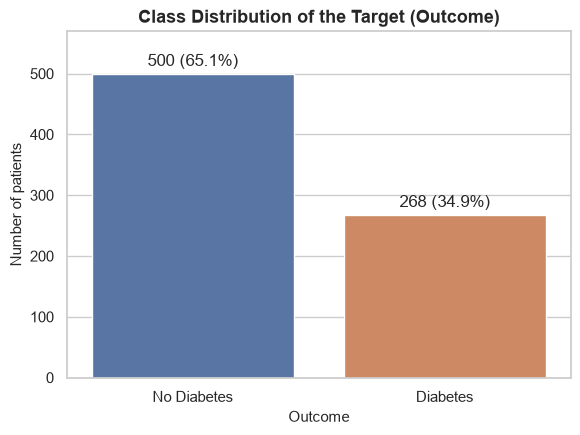

In [19]:
eda = replace_invalid_zeros(df_raw)        # zeros -> NaN for plotting (see Section 9.1)
eda["Diagnosis"] = eda[TARGET].map(OUTCOME_LABELS)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
order = ["No Diabetes", "Diabetes"]
sns.countplot(data=eda, x="Diagnosis", hue="Diagnosis", order=order, palette=PALETTE, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v)} ({v / len(eda) * 100:.1f}%)" for v in container.datavalues],
                 padding=3)
ax.set_title("Class Distribution of the Target (Outcome)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of patients")
ax.set_ylim(0, 570)
save_fig(fig, "03_outcome_distribution.png")
plt.show()

### 7.1 Distribution of each feature

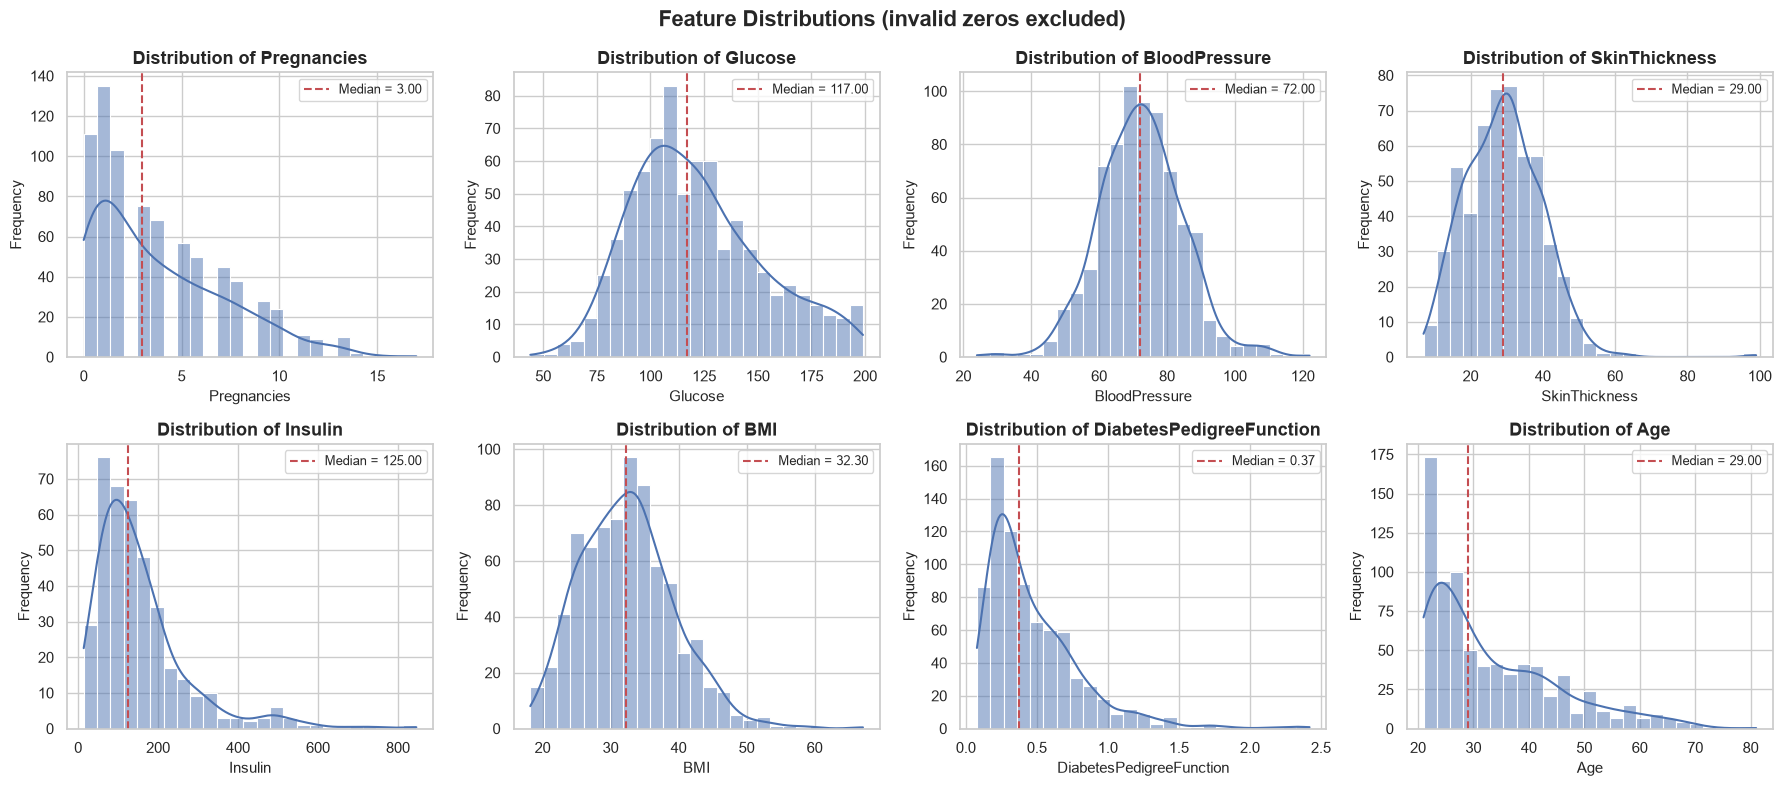

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(eda[col].dropna(), kde=True, bins=25, color="#4C72B0", ax=ax)
    ax.axvline(eda[col].median(), color="#C44E52", linestyle="--", label=f"Median = {eda[col].median():.2f}")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)
fig.suptitle("Feature Distributions (invalid zeros excluded)", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_feature_distributions.png")
plt.show()

### 7.2 Key features by Outcome

Overlaid density histograms compare the distribution of a feature for diabetic and non-diabetic patients. `common_norm=False` normalises each class separately so the shapes are comparable despite class imbalance.

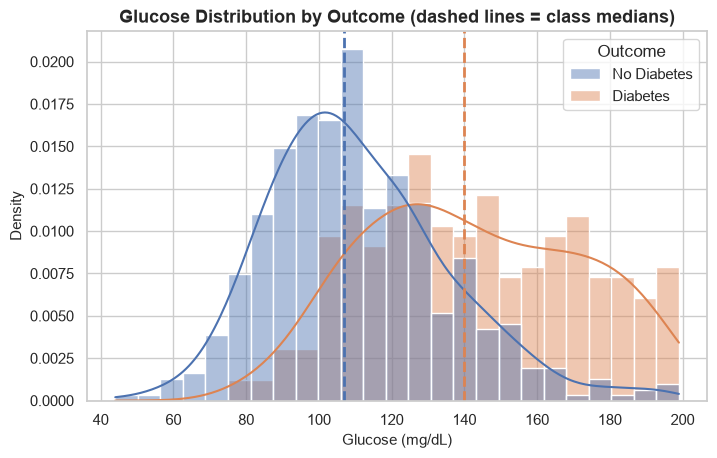

Diagnosis
No Diabetes    107.0
Diabetes       140.0


In [21]:
def plot_by_outcome(feature, filename, unit=""):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    sns.histplot(data=eda, x=feature, hue="Diagnosis", hue_order=order, palette=PALETTE,
                 kde=True, stat="density", common_norm=False, bins=25, alpha=0.45, ax=ax)
    for label in order:
        med = eda.loc[eda["Diagnosis"] == label, feature].median()
        ax.axvline(med, color=PALETTE[label], linestyle="--", linewidth=2)
    ax.set_title(f"{feature} Distribution by Outcome (dashed lines = class medians)")
    ax.set_xlabel(f"{feature}{unit}")
    ax.set_ylabel("Density")
    ax.get_legend().set_title("Outcome")
    save_fig(fig, filename)
    plt.show()
    print(eda.groupby("Diagnosis")[feature].median().reindex(order).rename(f"Median {feature}").to_string())

plot_by_outcome("Glucose", "05_glucose_by_outcome.png", " (mg/dL)")

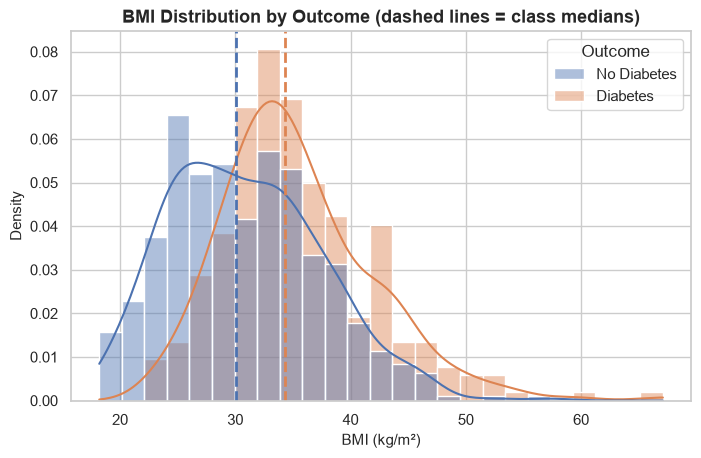

Diagnosis
No Diabetes    30.1
Diabetes       34.3


In [22]:
plot_by_outcome("BMI", "06_bmi_by_outcome.png", " (kg/m²)")

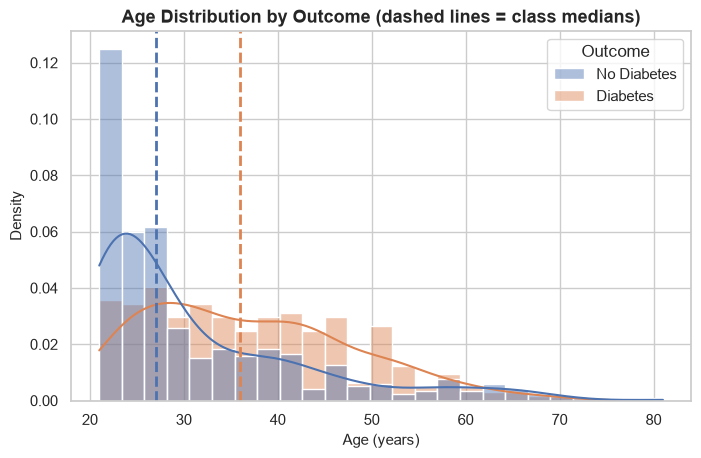

Diagnosis
No Diabetes    27.0
Diabetes       36.0


In [23]:
plot_by_outcome("Age", "07_age_by_outcome.png", " (years)")

### 7.3 Boxplots of all features by Outcome

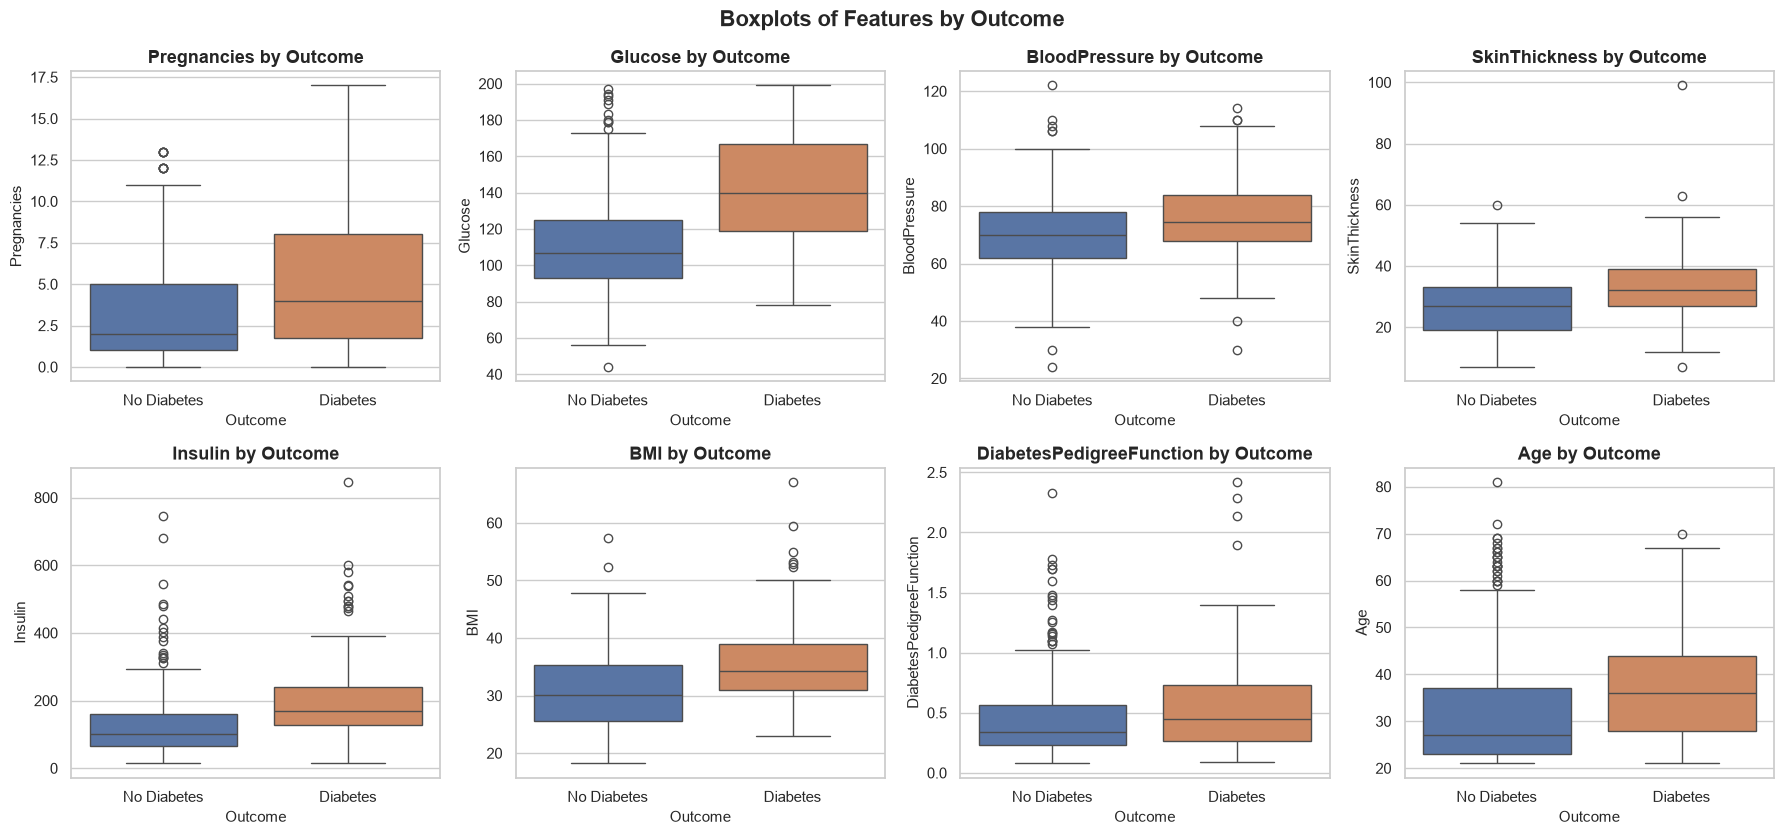

Diagnosis,No Diabetes,Diabetes
Pregnancies,2.00,4.00
Glucose,107.00,140.00
BloodPressure,70.00,74.50
SkinThickness,27.00,32.00
Insulin,102.50,169.50
BMI,30.10,34.30
DiabetesPedigreeFunction,0.34,0.45
Age,27.00,36.00


In [24]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=eda, x="Diagnosis", y=col, hue="Diagnosis", order=order, hue_order=order,
                palette=PALETTE, legend=False, ax=ax)
    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel(col)
fig.suptitle("Boxplots of Features by Outcome", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "08_boxplots_by_outcome.png")
plt.show()

eda.groupby("Diagnosis")[FEATURES].median().reindex(order).T.round(2)

### 7.4 Correlation heatmap

Pearson correlations are computed on pairwise-complete observations (NaNs ignored). Only the lower triangle is shown because the matrix is symmetric.

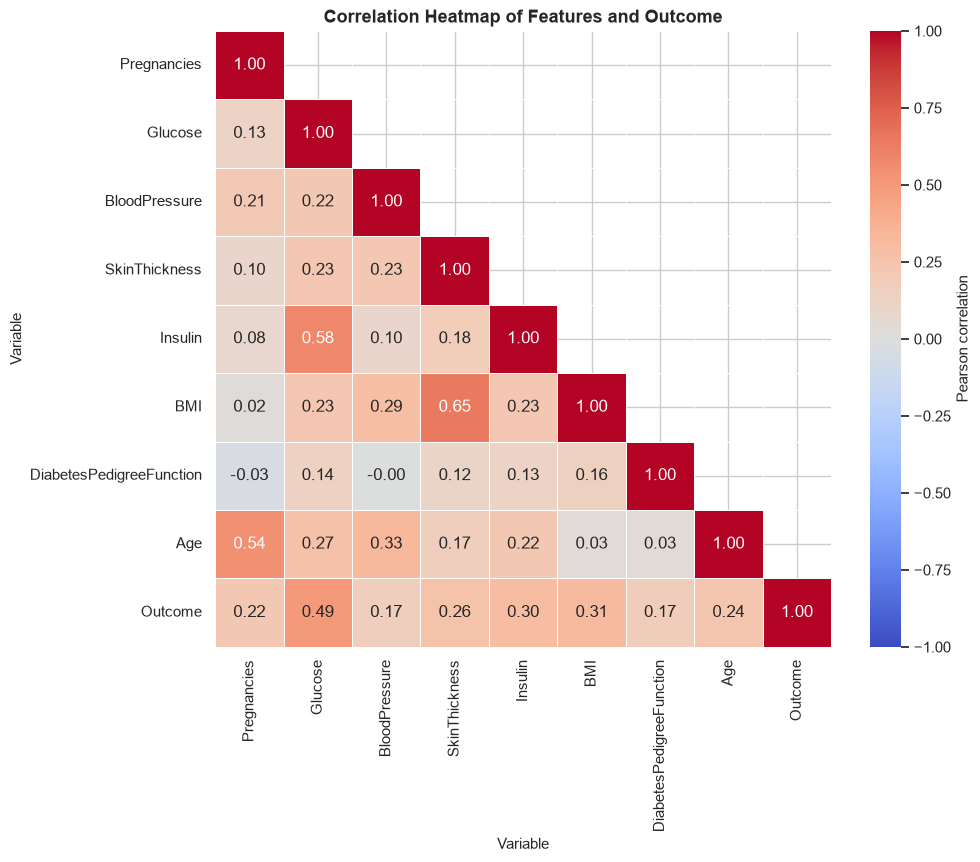

Correlation of each feature with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


In [25]:
corr = eda.drop(columns="Diagnosis").corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Features and Outcome")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
save_fig(fig, "09_correlation_heatmap.png")
plt.show()

print("Correlation of each feature with Outcome:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

### 7.5 Pairwise relationships of selected features

A full 8×8 pairplot is cluttered, so only the four features most correlated with the outcome are shown. Only the 392 patients with all four values recorded are plotted, because Insulin is missing for many patients.

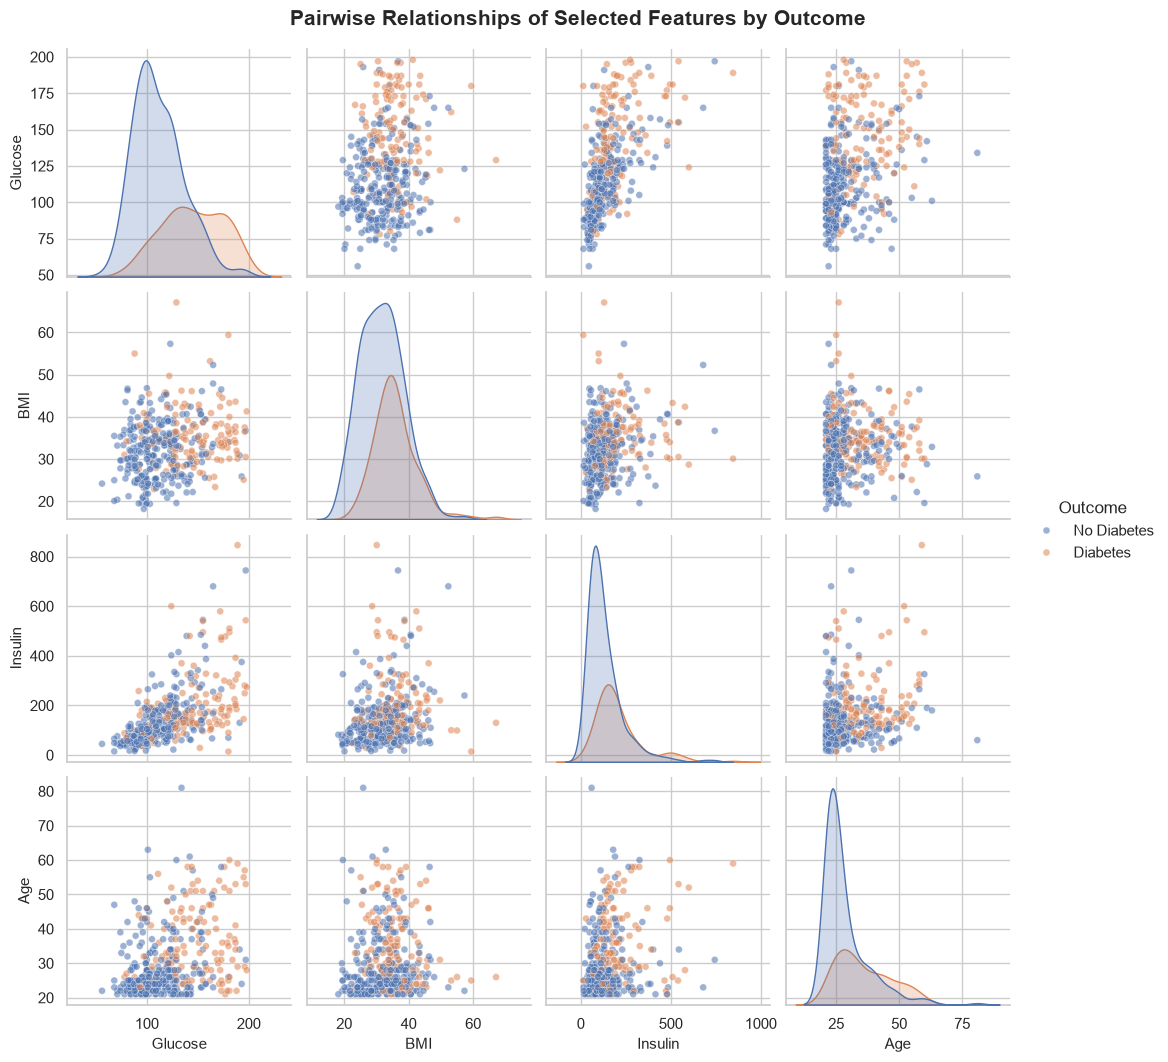

In [26]:
pair_cols = ["Glucose", "BMI", "Insulin", "Age"]
g = sns.pairplot(eda[pair_cols + ["Diagnosis"]].dropna(), hue="Diagnosis", hue_order=order,
                 palette=PALETTE, diag_kind="kde", plot_kws={"alpha": 0.55, "s": 25}, height=2.6)
g.figure.suptitle("Pairwise Relationships of Selected Features by Outcome", y=1.02,
                  fontsize=15, fontweight="bold")
g._legend.set_title("Outcome")
g.savefig(FIG_DIR / "10_pairplot_selected_features.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA interpretation

* **Glucose** shows the clearest separation between the classes. The median glucose of diabetic patients (140 mg/dL) is much higher than that of non-diabetic patients (107 mg/dL), and Glucose has the strongest correlation with Outcome (about 0.49). This suggests glucose will be an important predictor.
* **BMI** is higher on average in the diabetic group (median 34.3 vs. 30.1), with a moderate correlation of about 0.31.
* **Age** distributions differ: non-diabetic patients are concentrated in their 20s (median 27), while diabetic patients are spread more widely toward older ages (median 36).
* **Insulin** and **SkinThickness** are also higher in the diabetic group, but they have the most missing data, so their patterns should be interpreted with caution.
* **Feature-feature correlations**: SkinThickness–BMI (about 0.65), Glucose–Insulin (about 0.58) and Pregnancies–Age (about 0.54) are the strongest. These are moderate rather than extreme, so multicollinearity is not severe enough to require removing features.
* **Skewness and outliers**: Insulin, DiabetesPedigreeFunction, Age and Pregnancies are right-skewed. Median imputation and standard scaling are suitable for this.
* Every feature shows *overlap* between the two classes, so no single measurement separates them perfectly. A multivariate model is needed.

These are **associations** observed in this sample. They do not show that any measurement *causes* diabetes.

## 8. Exploratory Data Analysis – Dataset 2 (Early Stage)

Here we explore Dataset 2 visually. Because more than half of the rows are exact duplicates (Section 6.2), the plots use the **251 unique records**: otherwise duplicated people would be counted several times and distort the percentages. (The duplicate decision is discussed formally in Section 9.2.) EDA is descriptive only; nothing learned here is used by the models.

Unique records used for EDA: 251


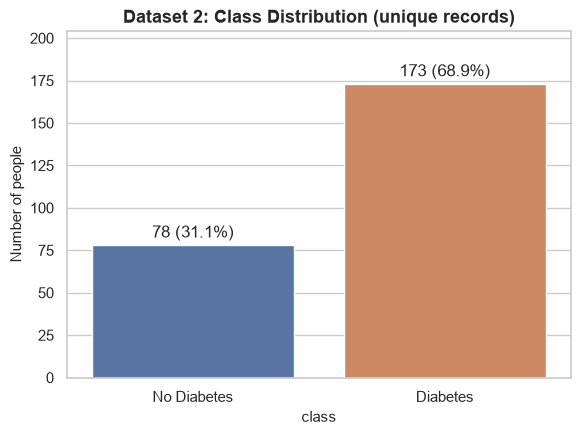

In [27]:
es_eda = clean_categories(es_raw).drop_duplicates().reset_index(drop=True)
es_eda["Diagnosis"] = encode_target(es_eda[ES_TARGET])[0].map(OUTCOME_LABELS)   # 1 -> "Diabetes"
print("Unique records used for EDA:", len(es_eda))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.countplot(data=es_eda, x="Diagnosis", hue="Diagnosis", order=order, palette=PALETTE, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v)} ({v / len(es_eda) * 100:.1f}%)" for v in container.datavalues],
                 padding=3)
ax.set_title("Dataset 2: Class Distribution (unique records)")
ax.set_xlabel("class")
ax.set_ylabel("Number of people")
ax.set_ylim(0, es_eda["Diagnosis"].value_counts().max() * 1.18)
save_fig(fig, "18_es_class_distribution.png")
plt.show()

### 8.1 Age by class

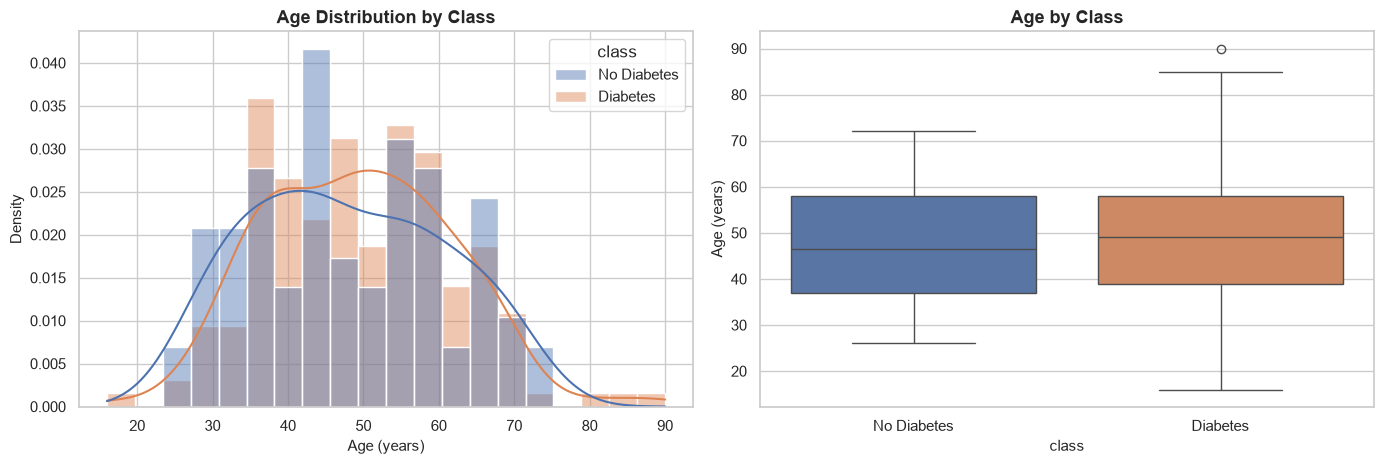

Diagnosis
No Diabetes    46.5
Diabetes       49.0


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(data=es_eda, x="Age", hue="Diagnosis", hue_order=order, palette=PALETTE, kde=True,
             stat="density", common_norm=False, bins=20, alpha=0.45, ax=axes[0])
axes[0].set_title("Age Distribution by Class")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")
axes[0].get_legend().set_title("class")
sns.boxplot(data=es_eda, x="Diagnosis", y="Age", hue="Diagnosis", order=order, hue_order=order,
            palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Age by Class")
axes[1].set_xlabel("class")
axes[1].set_ylabel("Age (years)")
fig.tight_layout()
save_fig(fig, "19_es_age_by_class.png")
plt.show()
print(es_eda.groupby("Diagnosis")["Age"].median().reindex(order).rename("Median age").to_string())

### 8.2 Gender and diabetes

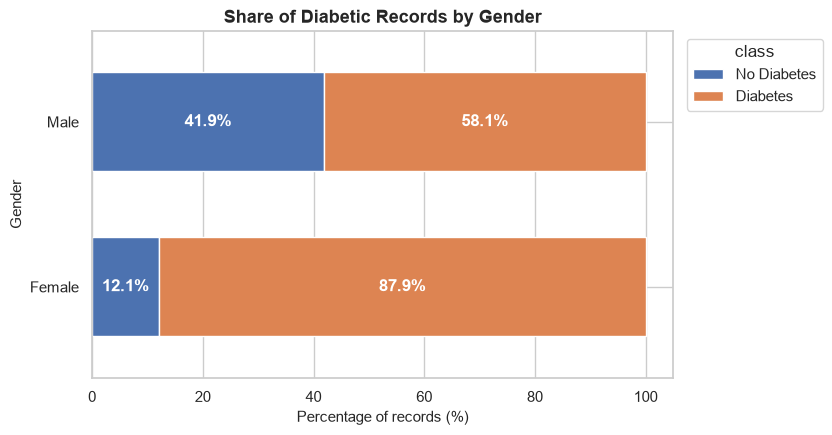

Diagnosis,No Diabetes,Diabetes,All
Gender,,,
Female,11,80,91
Male,67,93,160
All,78,173,251


In [29]:
gender_rate = pd.crosstab(es_eda["Gender"], es_eda["Diagnosis"], normalize="index")[order] * 100
fig, ax = plt.subplots(figsize=(7.5, 4.5))
gender_rate.plot(kind="barh", stacked=True, color=[PALETTE[c] for c in order], ax=ax, width=0.6)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
ax.set_title("Share of Diabetic Records by Gender")
ax.set_xlabel("Percentage of records (%)")
ax.set_ylabel("Gender")
ax.legend(title="class", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "20_es_gender_by_class.png")
plt.show()
pd.crosstab(es_eda["Gender"], es_eda["Diagnosis"], margins=True)[order + ["All"]]

### 8.3 How common is each symptom in each class?

For every Yes/No symptom we compare the percentage of **Yes** answers among diabetic and non-diabetic records. A large gap means the symptom is strongly associated with the class.

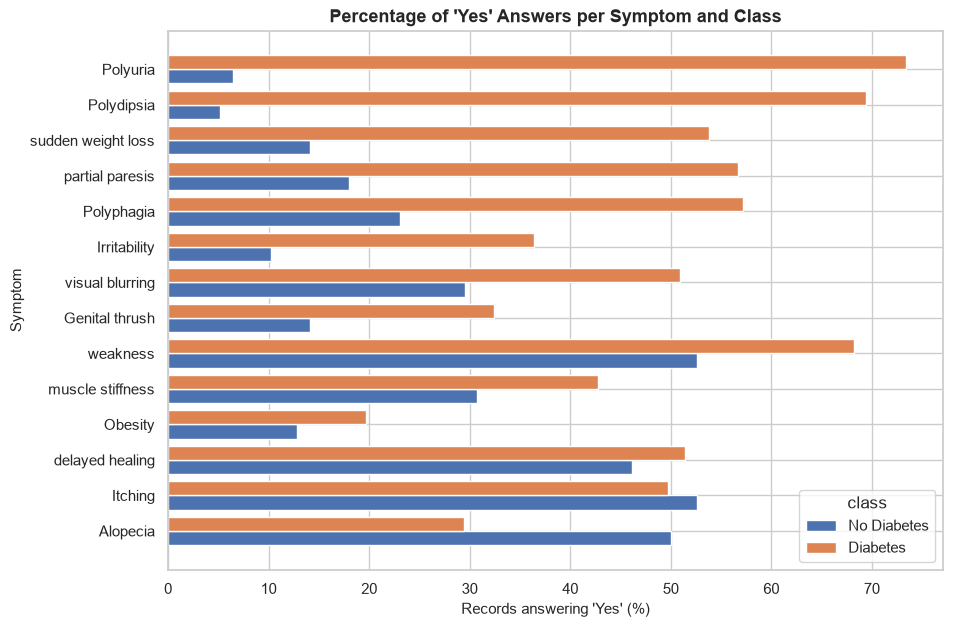

,No Diabetes,Diabetes,Difference (pp)
Polyuria,6.4,73.4,67.0
Polydipsia,5.1,69.4,64.2
sudden weight loss,14.1,53.8,39.7
partial paresis,17.9,56.6,38.7
Polyphagia,23.1,57.2,34.1
Irritability,10.3,36.4,26.2
visual blurring,29.5,50.9,21.4
Genital thrush,14.1,32.4,18.3
weakness,52.6,68.2,15.6
muscle stiffness,30.8,42.8,12.0


In [30]:
es_symptoms = [c for c in es_eda.columns
               if set(es_eda[c].dropna().unique()) <= {"Yes", "No"}]
prevalence = pd.DataFrame({
    label: (es_eda.loc[es_eda["Diagnosis"] == label, es_symptoms] == "Yes").mean() * 100 for label in order
})
prevalence["Difference (pp)"] = prevalence["Diabetes"] - prevalence["No Diabetes"]
prevalence = prevalence.sort_values("Difference (pp)")

fig, ax = plt.subplots(figsize=(10, 7))
y_pos = np.arange(len(prevalence))
ax.barh(y_pos - 0.2, prevalence["No Diabetes"], height=0.4, color=PALETTE["No Diabetes"], label="No Diabetes")
ax.barh(y_pos + 0.2, prevalence["Diabetes"], height=0.4, color=PALETTE["Diabetes"], label="Diabetes")
ax.set_yticks(y_pos)
ax.set_yticklabels(prevalence.index)
ax.set_title("Percentage of 'Yes' Answers per Symptom and Class")
ax.set_xlabel("Records answering 'Yes' (%)")
ax.set_ylabel("Symptom")
ax.legend(title="class", loc="lower right")
save_fig(fig, "21_es_symptom_prevalence.png")
plt.show()
prevalence.sort_values("Difference (pp)", ascending=False).round(1)

### 8.4 Association heatmap

For this plot only, Yes/Male/Positive are written as 1 and No/Female/Negative as 0. This is a fixed relabelling (nothing is learned from the data). For two 0/1 variables the Pearson correlation is the **phi coefficient**, a standard measure of association.

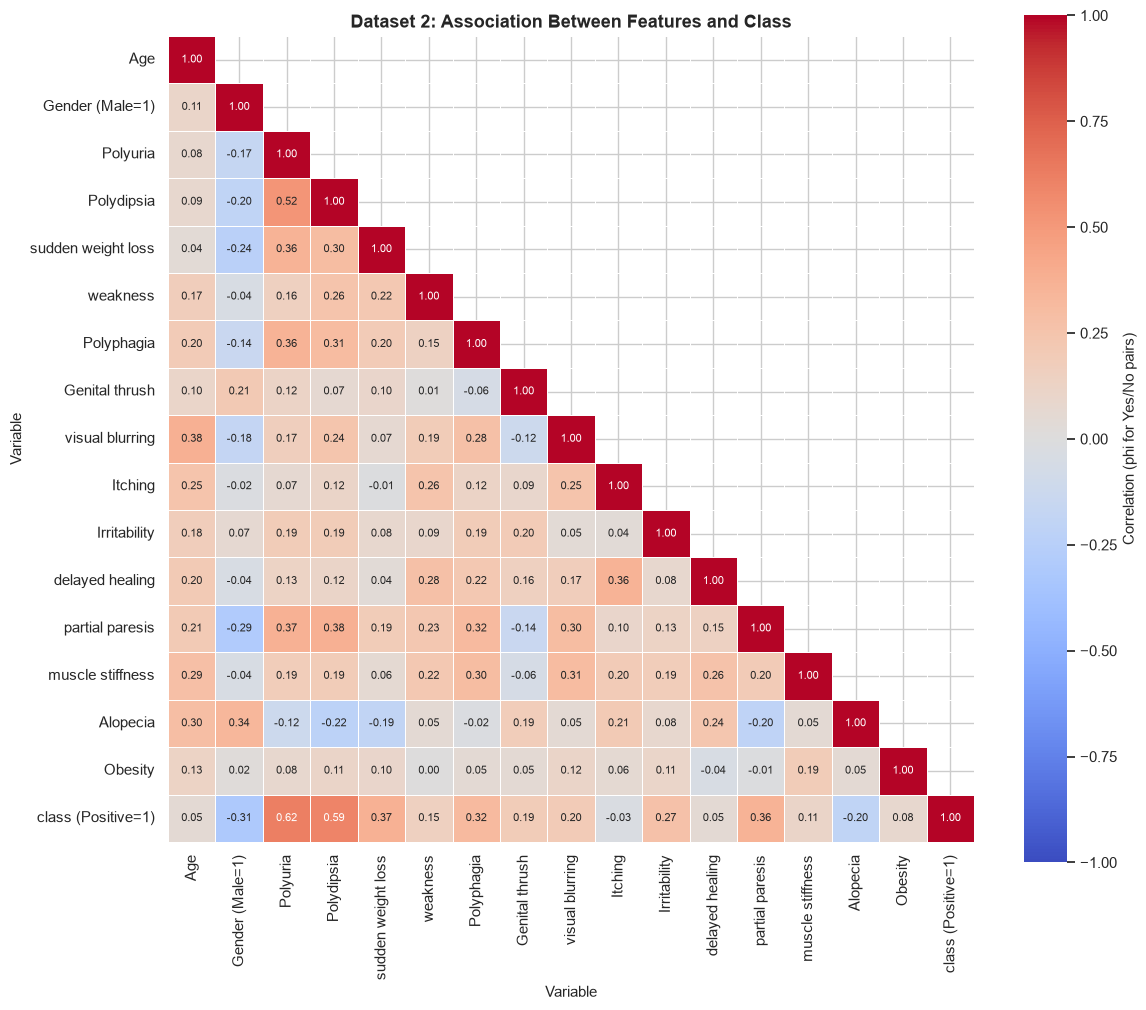

Association of each feature with class (Positive=1):
Polyuria              0.621
Polydipsia            0.595
sudden weight loss    0.373
partial paresis       0.360
Polyphagia            0.317
Irritability          0.269
visual blurring       0.199
Genital thrush        0.191
weakness              0.150
muscle stiffness      0.114
Obesity               0.083
Age                   0.053
delayed healing       0.049
Itching              -0.026
Alopecia             -0.198
Gender (Male=1)      -0.309


In [31]:
es_binary = es_eda.drop(columns=["Diagnosis", ES_TARGET]).replace(
    {"Yes": 1, "No": 0, "Male": 1, "Female": 0}).astype(float)
es_binary = es_binary.rename(columns={"Gender": "Gender (Male=1)"})
es_binary["class (Positive=1)"] = encode_target(es_eda[ES_TARGET])[0]
es_corr = es_binary.corr()
mask = np.triu(np.ones_like(es_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(es_corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.5, annot_kws={"size": 8}, cbar_kws={"label": "Correlation (phi for Yes/No pairs)"}, ax=ax)
ax.set_title("Dataset 2: Association Between Features and Class")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
save_fig(fig, "22_es_association_heatmap.png")
plt.show()
print("Association of each feature with class (Positive=1):")
print(es_corr["class (Positive=1)"].drop("class (Positive=1)").sort_values(ascending=False).round(3).to_string())

### EDA interpretation – Dataset 2

* **Polyuria** (excessive urination) and **Polydipsia** (excessive thirst) stand out: about 73 % and 69 % of diabetic records report them, against only 6 % and 5 % of non-diabetic records. These two classic symptoms have the strongest association with the class (correlation about 0.6).
* **Sudden weight loss**, **partial paresis** and **Polyphagia** (excessive hunger) are also clearly more frequent among diabetic records.
* **Gender** matters in this sample: 88 % of the women's records are diabetic, against 58 % of the men's. This reflects who attended this particular hospital and should not be read as a general medical fact.
* **Alopecia** is *more* common among non-diabetic records, so it is negatively associated with the class.
* **Age** differs only a little between the classes (median 49 vs 46.5), much less than in Pima.
* Unlike Pima, where only glucose was strongly separating, here **several features separate the classes strongly**. We should therefore expect Dataset 2 to be *easier* to predict.

These are associations in one hospital's questionnaire data, not causal effects.

## 9. Data Quality / Missing Values

Here we find and handle problems in the raw data: invalid values, missing values and duplicates. Only **fixed, row-by-row rules** are applied in this section (nothing is computed from the data), so it is safe to do this before the train/test split. Anything that *learns* from data, like filling missing values with a median, is postponed until after the split.

### 9.1 Dataset 1 – invalid zeros

Zero is treated as **invalid / missing** in five columns:

| Column | Why 0 is invalid |
|---|---|
| Glucose | plasma glucose cannot be 0 in a living patient |
| BloodPressure | diastolic blood pressure cannot be 0 |
| SkinThickness | triceps skin-fold thickness cannot be 0 mm |
| Insulin | 2-hour serum insulin of exactly 0 indicates "not measured" |
| BMI | body-mass index cannot be 0 |

Zeros are **kept** in `Pregnancies` (0 pregnancies is a valid value) and `Outcome` (0 is the negative class). `Age` and `DiabetesPedigreeFunction` contain no zeros.

In [32]:
zero_table = count_invalid_zeros(df_raw)
zero_table

,Invalid zeros,Percentage (%)
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


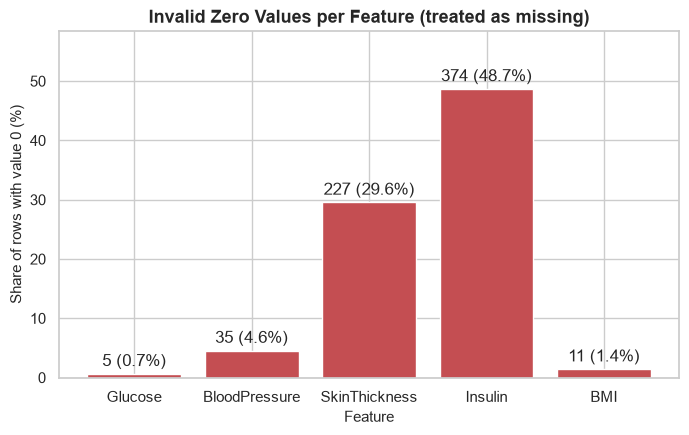

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(zero_table.index, zero_table["Percentage (%)"], color="#C44E52")
ax.bar_label(bars, labels=[f"{n} ({p:.1f}%)" for n, p in zip(zero_table["Invalid zeros"],
                                                            zero_table["Percentage (%)"])], padding=3)
ax.set_title("Invalid Zero Values per Feature (treated as missing)")
ax.set_xlabel("Feature")
ax.set_ylabel("Share of rows with value 0 (%)")
ax.set_ylim(0, zero_table["Percentage (%)"].max() * 1.2)
save_fig(fig, "02_invalid_zeros.png")
plt.show()

**Replacing invalid zeros with NaN.** Replacing a 0 with `NaN` is a fixed, row-by-row rule: it does not compute any statistic from the data, so doing it on the full dataset **cannot leak** information from the test set into training. The *imputation* of these NaNs (with a median) **does** learn a statistic, so it is deliberately postponed until after the train/test split (Section 10).

In [34]:
df = replace_invalid_zeros(df_raw)

missing = pd.DataFrame({"Missing after replacement": df.isna().sum(),
                        "Percentage (%)": (df.isna().mean() * 100).round(2)})
missing

,Missing after replacement,Percentage (%)
Pregnancies,0,0.00
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


Insulin (about 49 % missing) and SkinThickness (about 30 % missing) have substantial missingness. Dropping these rows would discard roughly half of the dataset, so imputation is preferred. The **median** is used instead of the mean because Insulin and SkinThickness are right-skewed and the median is robust to outliers.

In [35]:
# Save the cleaned Dataset 1 (zeros -> NaN; nothing imputed yet) for reference
df.to_csv(PROCESSED_DIR / "pima_zeros_as_nan.csv", index=False)
print("Saved:", (PROCESSED_DIR / "pima_zeros_as_nan.csv").relative_to(PROJECT_ROOT))

Saved: data/processed/pima_zeros_as_nan.csv


### 9.2 Dataset 2 – unknown values and duplicates

**Unknown / missing values.** Survey files often hide missing answers as text such as `"?"`, `"unknown"` or an empty string. `clean_categories()` trims spaces, unifies Yes/No spelling and turns such tokens into real `NaN` values, which the pipeline would later impute (most frequent value, learned on the training data only).

In [36]:
es_clean = clean_categories(es_raw)
print("Unknown-style tokens converted to NaN:", int(es_clean.isna().sum().sum() - es_raw.isna().sum().sum()))
missing_value_table(es_clean).T

Unknown-style tokens converted to NaN: 0


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
Missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Percentage (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Duplicates.** Here we check the duplicated rows found in Section 6.2 and decide how to handle them.

In [37]:
es_features = [c for c in es_clean.columns if c != ES_TARGET]
n_dup = int(es_clean.duplicated().sum())
conflicts = int((es_clean.drop_duplicates().groupby(es_features)[ES_TARGET].nunique() > 1).sum())
print(f"Exact duplicate rows             : {n_dup} of {len(es_clean)} ({n_dup / len(es_clean) * 100:.1f} %)")
print(f"Same features, different label   : {conflicts}")

es = es_clean.drop_duplicates().reset_index(drop=True)      # the dataset used from now on

before = es_clean[ES_TARGET].value_counts()
after = es[ES_TARGET].value_counts()
pd.DataFrame({"Before (all rows)": before, "% before": (before / before.sum() * 100).round(1),
              "After (unique records)": after, "% after": (after / after.sum() * 100).round(1)})

Exact duplicate rows             : 269 of 520 (51.7 %)
Same features, different label   : 0


,Before (all rows),% before,After (unique records),% after
class,,,,
Positive,320,61.5,173,68.9
Negative,200,38.5,78,31.1


**Decision: remove exact duplicates before splitting.**

* Every feature in this dataset is a short answer (Yes/No, Male/Female, an age), so an identical row means an **identical record**, and no duplicate group has conflicting labels.
* If duplicates stay in the data, a random train/test split puts copies of the same record into **both** sets. The model is then tested on records it has already seen during training. That is **data leakage**, and it makes the scores look better than they really are.
* Removing exact duplicates is a fixed rule that learns nothing from the data, so doing it before the split is safe.
* Cost: the dataset shrinks from 520 to **251 unique records**, and the positive class grows to about 69 %. Section 15.2 shows how much the duplicates would have inflated the results.

In [38]:
es.to_csv(PROCESSED_DIR / "early_stage_unique.csv", index=False)
print("Saved:", (PROCESSED_DIR / "early_stage_unique.csv").relative_to(PROJECT_ROOT), "-", es.shape)

Saved: data/processed/early_stage_unique.csv - (251, 17)


## 10. Preprocessing – Dataset 1 (Data Transformation)

**Steps**

1. Invalid zeros have already been replaced with NaN (Section 9.1).
2. Separate features `X` from the target `y`.
3. **Split into training (80 %) and test (20 %) sets before fitting anything**, using `stratify=y` so both sets keep the 65/35 class ratio.
4. Fit a **median imputer** on the training set only and use it to fill NaNs in both sets.
5. Fit a **StandardScaler** on the training set only and use it to transform both sets.

**Why the test set must not influence preprocessing.** The test set represents future, unseen patients. If imputation medians or scaling means were computed on the full dataset, information about the test patients would be built into the training process. That is **data leakage**, and it makes evaluation scores optimistically biased. Fitting every transformer on the training data only keeps the test evaluation honest.

In [39]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=RANDOM_STATE)
# equivalent to: train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "No Diabetes (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Diabetes (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "Diabetes share (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Training set", "Test set"])
split_summary

,Rows,No Diabetes (0),Diabetes (1),Diabetes share (%)
Training set,614,400,214,34.85
Test set,154,100,54,35.06


In [40]:
preprocessor = build_preprocessor(scale=True)          # median imputer + StandardScaler (unfitted)
X_train_prep = preprocessor.fit_transform(X_train)     # FIT on training data only
X_test_prep = preprocessor.transform(X_test)           # only TRANSFORM the test data

learned = pd.DataFrame({
    "Imputation median (train)": preprocessor.named_steps["imputer"].statistics_,
    "Scaler mean (train)": preprocessor.named_steps["scaler"].mean_,
    "Scaler std (train)": preprocessor.named_steps["scaler"].scale_,
}, index=FEATURES).round(3)
print("Missing values after preprocessing -> train:", np.isnan(X_train_prep).sum(),
      "| test:", np.isnan(X_test_prep).sum())
learned

Missing values after preprocessing -> train: 0 | test: 0


,Imputation median (train),Scaler mean (train),Scaler std (train)
Pregnancies,3.000,3.819,3.311
Glucose,117.000,121.671,29.979
BloodPressure,72.000,72.140,12.265
SkinThickness,29.000,29.042,8.885
Insulin,125.000,137.705,78.701
BMI,32.400,32.448,6.819
DiabetesPedigreeFunction,0.382,0.477,0.330
Age,29.000,33.366,11.824


The table shows the statistics **learned from the 614 training rows only**. The same medians, means and standard deviations are then applied to the 154 test rows. After preprocessing there are no missing values left.

### 10.1 Handling Class Imbalance – Dataset 1

**Why imbalance matters.** With 65 % negatives, a classifier can reach high accuracy by favouring the majority class while missing many diabetic patients. In a screening setting, missed positive cases (false negatives) are especially undesirable.

**SMOTE (Synthetic Minority Over-sampling Technique)** creates new synthetic minority-class examples by interpolating between a minority sample and one of its nearest minority-class neighbours. This balances the training data without simply duplicating rows.

**Rules followed**

* SMOTE is applied **only to the training data**, after the split. Applying it before the split would place synthetic copies derived from test patients into training (leakage) and would distort the test set's real class ratio.
* SMOTE is applied **after imputation and scaling**, because SMOTE uses distances and cannot handle NaNs.
* In the modelling pipelines (Section 12), SMOTE is placed *inside* an `imblearn` pipeline, so during cross-validation it is applied to each training fold only, never to the validation fold.

The cell below demonstrates the effect of SMOTE on the preprocessed training set.

In [41]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_prep, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_train_smote).value_counts().sort_index()
smote_table = pd.DataFrame({"Before SMOTE": before, "After SMOTE": after})
smote_table.index = [OUTCOME_LABELS[i] for i in smote_table.index]
print("Test set is NOT resampled:", y_test.value_counts().sort_index().to_dict())
smote_table

Test set is NOT resampled: {0: 100, 1: 54}


,Before SMOTE,After SMOTE
No Diabetes,400,400
Diabetes,214,400


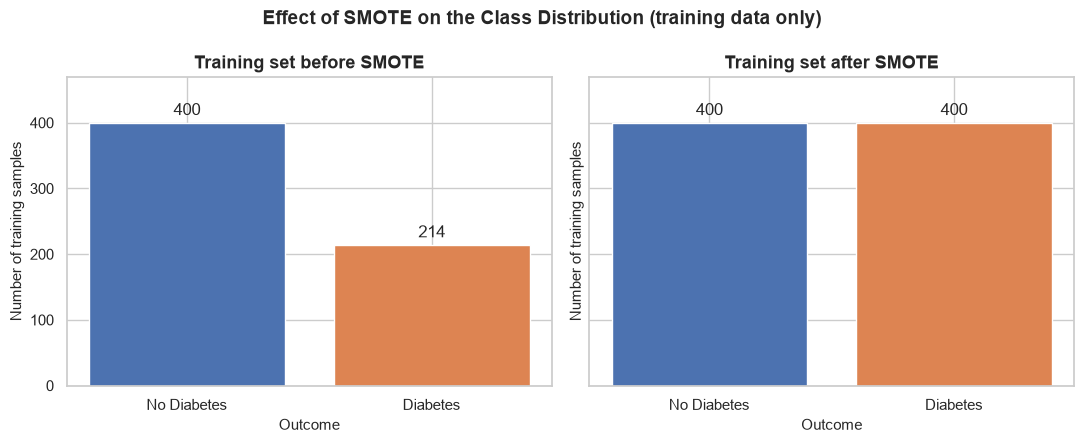

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (title, counts) in zip(axes, [("Training set before SMOTE", before),
                                       ("Training set after SMOTE", after)]):
    labels = [OUTCOME_LABELS[i] for i in counts.index]
    bars = ax.bar(labels, counts.values, color=[PALETTE[l] for l in labels])
    ax.bar_label(bars, padding=3)
    ax.set_title(title)
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Number of training samples")
axes[0].set_ylim(0, 470)
fig.suptitle("Effect of SMOTE on the Class Distribution (training data only)", fontsize=14,
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "11_smote_class_distribution.png")
plt.show()

**Alternative: `class_weight="balanced"`.** Instead of creating synthetic rows, some algorithms (e.g. Logistic Regression, Decision Tree, Random Forest) can give larger weight to errors on the minority class. As a quick check, we compare three ways of handling imbalance for Logistic Regression using **5-fold stratified cross-validation on the training set only**:

1. no imbalance handling,
2. `class_weight="balanced"`,
3. SMOTE inside the pipeline.

Using both SMOTE *and* class weights together would compensate for the imbalance twice, so the main experiments use SMOTE alone.

In [43]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variants = {
    "No imbalance handling": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                            use_smote=False),
    "class_weight='balanced'": build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                                 random_state=RANDOM_STATE), use_smote=False),
    "SMOTE": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), use_smote=True),
}
rows = []
for name, pipe in variants.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    rows.append({"Strategy": name, "CV Accuracy": s["test_accuracy"].mean(), "CV Recall": s["test_recall"].mean(),
                 "CV F1": s["test_f1"].mean(), "CV ROC-AUC": s["test_roc_auc"].mean()})
imbalance_comparison = pd.DataFrame(rows).set_index("Strategy").round(4)
imbalance_comparison

,CV Accuracy,CV Recall,CV F1,CV ROC-AUC
Strategy,,,,
No imbalance handling,0.7882,0.5748,0.6545,0.8434
class_weight='balanced',0.7622,0.7010,0.6724,0.8444
SMOTE,0.7720,0.7244,0.6885,0.8427


Without imbalance handling, Logistic Regression keeps slightly higher accuracy but its **recall drops sharply**, so it misses many more diabetic patients. Both SMOTE and `class_weight="balanced"` raise recall substantially for a small cost in accuracy, and ROC-AUC stays almost unchanged. This is expected: ROC-AUC measures *ranking* quality, while imbalance handling mainly shifts the decision boundary toward the minority class. Both approaches give similar results here; SMOTE is used for all five models because it works the same way for every algorithm, including KNN, which has no `class_weight` option.

## 11. Preprocessing – Dataset 2 (Data Transformation)

**Steps**

1. **Encode the target**: the automatically identified `class` column becomes 1 (Positive) / 0 (Negative).
2. Separate the features `es_X` from the target `es_y`, and detect **numeric** and **categorical** features from their data types.
3. **Split into training (80 %) and test (20 %) sets before fitting anything**, with `stratify=es_y`.
4. Inside the modelling pipeline, a `ColumnTransformer` learns on the **training data only**:
   * numeric (`Age`): median imputation → standard scaling;
   * categorical (Gender and symptoms): most-frequent imputation → **one-hot encoding**. Binary columns become a single 0/1 column (`drop="if_binary"`), and categories never seen in training are ignored safely.

As for Dataset 1, the test set must not influence any of these steps, otherwise information about the test records would leak into training.

In [44]:
es_y, ES_TARGET_MAPPING = encode_target(es[ES_TARGET])
es_X = es.drop(columns=ES_TARGET)
ES_NUMERIC, ES_CATEGORICAL = feature_types(es_X)

print("Target encoding     :", ES_TARGET_MAPPING)
print("Numeric features    :", ES_NUMERIC)
print("Categorical features:", ES_CATEGORICAL)

Target encoding     : {'Positive': 1, 'Negative': 0}
Numeric features    : ['Age']
Categorical features: ['Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity']


Here we split the data **before** fitting any preprocessing step, to avoid data leakage.

In [45]:
es_X_train, es_X_test, es_y_train, es_y_test = train_test_split(
    es_X, es_y, test_size=0.2, stratify=es_y, random_state=RANDOM_STATE)

pd.DataFrame({
    "Rows": [len(es_X_train), len(es_X_test)],
    "Negative (0)": [(es_y_train == 0).sum(), (es_y_test == 0).sum()],
    "Positive (1)": [(es_y_train == 1).sum(), (es_y_test == 1).sum()],
    "Positive share (%)": [round(es_y_train.mean() * 100, 2), round(es_y_test.mean() * 100, 2)],
}, index=["Training set", "Test set"])

,Rows,Negative (0),Positive (1),Positive share (%)
Training set,200,62,138,69.00
Test set,51,16,35,68.63


Here we fit the preprocessing step on the training data only, to show what the models will receive.

In [46]:
es_preprocessor = build_es_preprocessor(ES_NUMERIC, ES_CATEGORICAL)
es_X_train_prep = es_preprocessor.fit_transform(es_X_train)    # FIT on training data only
es_X_test_prep = es_preprocessor.transform(es_X_test)          # only TRANSFORM the test data
ES_FEATURE_NAMES = clean_feature_names(es_preprocessor.get_feature_names_out())

print("Shape after preprocessing -> train:", es_X_train_prep.shape, "| test:", es_X_test_prep.shape)
print("Missing values after preprocessing:", int(np.isnan(es_X_train_prep).sum() + np.isnan(es_X_test_prep).sum()))
pd.DataFrame(es_X_train_prep[:5], columns=ES_FEATURE_NAMES).round(3)

Shape after preprocessing -> train: (200, 16) | test: (51, 16)
Missing values after preprocessing: 0


,Age,Gender = Male,Polyuria = Yes,Polydipsia = Yes,sudden weight loss = Yes,weakness = Yes,Polyphagia = Yes,Genital thrush = Yes,visual blurring = Yes,Itching = Yes,Irritability = Yes,delayed healing = Yes,partial paresis = Yes,muscle stiffness = Yes,Alopecia = Yes,Obesity = Yes
0,-1.678,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-0.792,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,-0.067,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
3,0.577,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,-1.517,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


`Age` is now standardised (mean and standard deviation learned from the 200 training records) and every Yes/No or Male/Female column is a single 0/1 column, e.g. `Polyuria = Yes`.

### 11.1 Handling Class Imbalance – Dataset 2

In Dataset 2 the classes are imbalanced in the **opposite direction** to Pima: about 69 % of the unique records are **diabetic**, so the *minority* class is "no diabetes".

* **Why not SMOTE here?** After encoding, the features are 0/1 answers. SMOTE creates new records by interpolating between neighbours, which would produce impossible answers such as `Polyuria = 0.37`.
* **Alternative: class weights.** `class_weight="balanced"` (and `scale_pos_weight` for XGBoost) gives more weight to errors on the minority class. Here the minority class is the *non-diabetic* class, so balancing would push the models **away** from predicting diabetes and could lower recall, which matters most for screening.

Instead of assuming, we compare **no re-weighting** and **balanced class weights** with 5-fold cross-validation **on the training data only**, and keep the option with the higher average recall.

In [47]:
es_spw = (es_y_train == 0).sum() / (es_y_train == 1).sum()   # learned from the training labels only
es_imbalance_rows = []
for label, weight, spw in [("No re-weighting", None, 1.0), ("class_weight='balanced'", "balanced", es_spw)]:
    cv_table = cross_validate_models(get_es_models(ES_NUMERIC, ES_CATEGORICAL, class_weight=weight,
                                                   scale_pos_weight=spw),
                                     es_X_train, es_y_train, cv_splits=5, random_state=RANDOM_STATE)
    es_imbalance_rows.append({"Strategy": label,
                              "CV Accuracy": cv_table["CV accuracy mean"].mean(),
                              "CV Precision": cv_table["CV precision mean"].mean(),
                              "CV Recall": cv_table["CV recall mean"].mean(),
                              "CV F1": cv_table["CV f1 mean"].mean(),
                              "CV ROC-AUC": cv_table["CV roc_auc mean"].mean()})
es_imbalance_comparison = pd.DataFrame(es_imbalance_rows).set_index("Strategy").round(4)

best_strategy = es_imbalance_comparison["CV Recall"].idxmax()
ES_CLASS_WEIGHT = None if best_strategy == "No re-weighting" else "balanced"
ES_SCALE_POS_WEIGHT = 1.0 if ES_CLASS_WEIGHT is None else es_spw
print("Averages over the five models. Chosen strategy:", best_strategy)
es_imbalance_comparison

Averages over the five models. Chosen strategy: No re-weighting


,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Strategy,,,,,
No re-weighting,0.899,0.9473,0.9071,0.924,0.9591
class_weight='balanced',0.888,0.9581,0.8780,0.914,0.9632


Balancing the classes makes the models more cautious about predicting diabetes, which raises precision but **lowers recall**. Because the screening goal is to miss as few diabetic people as possible, **no re-weighting** is kept for Dataset 2. This choice was made with cross-validation on the training data only; the test set was not used.

## 12. Predictive Modelling – Dataset 1 (Model Selection and Training)

Five classifiers of increasing complexity are compared:

| Model | Idea | Needs scaling? | Settings used |
|---|---|---|---|
| **Logistic Regression** | Linear model of the log-odds; interpretable baseline | Yes | `max_iter=1000` |
| **K-Nearest Neighbors** | Majority vote of the *k* most similar patients | Yes (distance-based) | `n_neighbors=15` |
| **Decision Tree** | A sequence of if/else splits on features | No | `max_depth=5`, `min_samples_leaf=5` (limits overfitting) |
| **Random Forest** | Many decorrelated trees, averaged (bagging) | No | `n_estimators=300`, `min_samples_leaf=2` |
| **XGBoost** | Trees built sequentially to correct earlier errors (boosting) | No | `n_estimators=200`, `max_depth=3`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8` |

These are reasonable, conservative settings rather than the result of an exhaustive hyperparameter search. All models use `random_state=42` where supported.

**A single consistent pipeline for every model**

```
SimpleImputer(median) → StandardScaler → SMOTE → Classifier
```

Scaling is essential for Logistic Regression and KNN. Tree-based models do not need it, because a monotonic rescaling does not change which splits are possible. Scaling is still kept for them because it (a) keeps one consistent methodology and (b) puts features on comparable scales for SMOTE's nearest-neighbour search. Because everything is inside one `imblearn` pipeline, calling `.fit()` learns imputation, scaling and SMOTE from the training data only.

In [48]:
models = get_models(random_state=RANDOM_STATE)
models["Random Forest"]   # example of one complete pipeline

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True


### 12.1 Cross-validation on the training set – Dataset 1

Before touching the test set, each pipeline is evaluated with **5-fold stratified cross-validation on the 614 training rows**. In each fold, imputation, scaling and SMOTE are re-fitted on the four training folds only. The mean and standard deviation across folds show how stable each model is. No hyperparameters are tuned on the test set.

In [49]:
cv_results = cross_validate_models(models, X_train, y_train, cv_splits=5, random_state=RANDOM_STATE)
cv_display = pd.DataFrame({
    m: cv_results[f"CV {k} mean"].round(3).astype(str) + " ± " + cv_results[f"CV {k} std"].round(3).astype(str)
    for m, k in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall", "recall"),
                 ("F1", "f1"), ("ROC-AUC", "roc_auc")]
})
cv_display

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.772 ± 0.015,0.658 ± 0.026,0.724 ± 0.045,0.689 ± 0.021,0.843 ± 0.02
K-Nearest Neighbors,0.728 ± 0.054,0.588 ± 0.07,0.79 ± 0.02,0.672 ± 0.047,0.82 ± 0.045
Decision Tree,0.697 ± 0.029,0.56 ± 0.047,0.687 ± 0.069,0.612 ± 0.013,0.762 ± 0.013
Random Forest,0.779 ± 0.009,0.672 ± 0.022,0.715 ± 0.028,0.692 ± 0.009,0.829 ± 0.025
XGBoost,0.751 ± 0.027,0.632 ± 0.041,0.687 ± 0.058,0.657 ± 0.04,0.822 ± 0.03


### 12.2 Final training on the full training set – Dataset 1

Each pipeline is now fitted once on all 614 training rows (imputation → scaling → SMOTE → classifier).

In [50]:
models = train_models(models, X_train, y_train)

Trained: Logistic Regression
Trained: K-Nearest Neighbors
Trained: Decision Tree
Trained: Random Forest


Trained: XGBoost


## 13. Predictive Modelling – Dataset 2

To make the comparison meaningful, Dataset 2 uses the **same five model families with the same settings** as Dataset 1 (Logistic Regression, KNN with k = 15, Decision Tree with depth 5, Random Forest with 300 trees, XGBoost with 200 shallow trees), all with `random_state=42`. If XGBoost is not installed it is skipped.

**Pipeline for every model**

```
ColumnTransformer (Age: median + scaling | categories: most-frequent + one-hot) → Classifier
```

The whole pipeline is fitted with `.fit()`, so every learned step uses the training data only. There is no SMOTE step (see Section 11.1).

In [51]:
es_models = get_es_models(ES_NUMERIC, ES_CATEGORICAL, class_weight=ES_CLASS_WEIGHT,
                          scale_pos_weight=ES_SCALE_POS_WEIGHT, random_state=RANDOM_STATE)
es_models["Random Forest"]   # example of one complete pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

### 13.1 Cross-validation on the training set – Dataset 2

Here each pipeline is evaluated with **5-fold stratified cross-validation on the 200 training records**; the preprocessing is re-fitted inside every fold. The test set is not touched.

In [52]:
es_cv_results = cross_validate_models(es_models, es_X_train, es_y_train, cv_splits=5, random_state=RANDOM_STATE)
pd.DataFrame({
    m: es_cv_results[f"CV {k} mean"].round(3).astype(str) + " ± " + es_cv_results[f"CV {k} std"].round(3).astype(str)
    for m, k in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall", "recall"),
                 ("F1", "f1"), ("ROC-AUC", "roc_auc")]
})

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.89 ± 0.025,0.928 ± 0.028,0.913 ± 0.059,0.919 ± 0.022,0.972 ± 0.009
K-Nearest Neighbors,0.86 ± 0.03,0.984 ± 0.02,0.811 ± 0.056,0.888 ± 0.031,0.966 ± 0.023
Decision Tree,0.885 ± 0.03,0.924 ± 0.048,0.913 ± 0.056,0.916 ± 0.024,0.9 ± 0.045
Random Forest,0.925 ± 0.027,0.951 ± 0.027,0.942 ± 0.048,0.945 ± 0.021,0.977 ± 0.013
XGBoost,0.935 ± 0.02,0.95 ± 0.016,0.957 ± 0.035,0.953 ± 0.015,0.98 ± 0.007


### 13.2 Final training on the full training set – Dataset 2

In [53]:
es_models = train_models(es_models, es_X_train, es_y_train)

Trained: Logistic Regression
Trained: K-Nearest Neighbors
Trained: Decision Tree
Trained: Random Forest


Trained: XGBoost


## 14. Model Evaluation

Here the fitted models of each dataset are evaluated on their **untouched test sets** (Dataset 1: 154 patients; Dataset 2: 51 unique records), using the same five metrics for both:

| Metric | Meaning | Formula |
|---|---|---|
| Accuracy | Share of all predictions that are correct | (TP + TN) / total |
| Precision | Of patients predicted diabetic, how many truly are | TP / (TP + FP) |
| Recall (sensitivity) | Of truly diabetic patients, how many the model catches | TP / (TP + FN) |
| F1 score | Harmonic mean of precision and recall | 2·P·R / (P + R) |
| ROC-AUC | Ability to rank diabetic patients above non-diabetic ones across all thresholds | area under ROC curve |

Specificity, TN / (TN + FP), is also reported. Predictions use the default probability threshold of 0.5.

### 14.1 Dataset 1 – Pima

In [54]:
print_classification_reports(models, X_test, y_test)

Logistic Regression
              precision    recall  f1-score   support

 No Diabetes      0.796     0.740     0.767       100
    Diabetes      0.574     0.648     0.609        54

    accuracy                          0.708       154
   macro avg      0.685     0.694     0.688       154
weighted avg      0.718     0.708     0.711       154

K-Nearest Neighbors
              precision    recall  f1-score   support

 No Diabetes      0.844     0.650     0.734       100
    Diabetes      0.545     0.778     0.641        54

    accuracy                          0.695       154
   macro avg      0.695     0.714     0.688       154
weighted avg      0.739     0.695     0.702       154

Decision Tree
              precision    recall  f1-score   support

 No Diabetes      0.854     0.700     0.769       100
    Diabetes      0.583     0.778     0.667        54

    accuracy                          0.727       154
   macro avg      0.718     0.739     0.718       154
weighted avg      0.

In [55]:
results = evaluate_models(models, X_test, y_test)      # sorted by ROC-AUC (descending)
main_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

model_comparison = results[["Model"] + main_metrics].round(4)
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

metrics = results.merge(cv_results.round(4), left_on="Model", right_index=True)
metrics.round(4).to_csv(RESULTS_DIR / "metrics.csv", index=False)

print("Saved:", (RESULTS_DIR / "model_comparison.csv").relative_to(PROJECT_ROOT))
print("Saved:", (RESULTS_DIR / "metrics.csv").relative_to(PROJECT_ROOT))
model_comparison

Saved: results/model_comparison.csv
Saved: results/metrics.csv


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.7532,0.6250,0.7407,0.6780,0.8263
1,Logistic Regression,0.7078,0.5738,0.6481,0.6087,0.8113
2,Random Forest,0.7468,0.6154,0.7407,0.6723,0.8094
3,K-Nearest Neighbors,0.6948,0.5455,0.7778,0.6412,0.7974
4,Decision Tree,0.7273,0.5833,0.7778,0.6667,0.7616


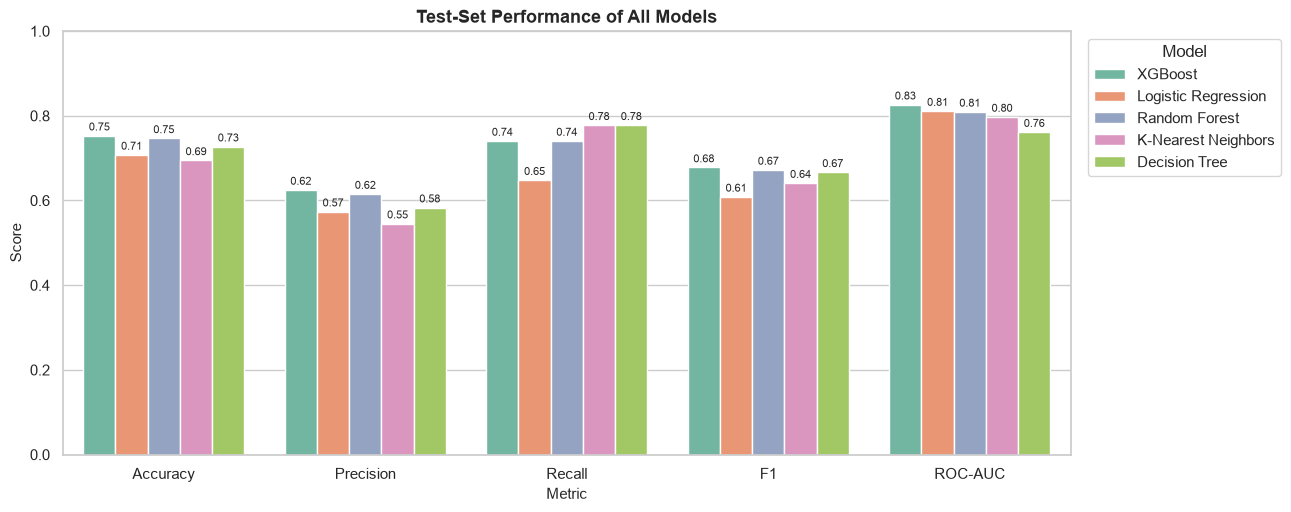

In [56]:
plot_df = model_comparison.melt(id_vars="Model", value_vars=main_metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Test-Set Performance of All Models")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "12_model_comparison.png")
plt.show()

#### Confusion matrices – Dataset 1

A confusion matrix breaks the predictions down into four cells:

| | Predicted Negative | Predicted Positive |
|---|---|---|
| **Actual Negative** | **TN** – correctly predicted as no diabetes | **FP** – healthy patient flagged as diabetic (false alarm) |
| **Actual Positive** | **FN** – diabetic patient missed by the model | **TP** – diabetic patient correctly flagged |

**Why false negatives matter in screening.** In a screening workflow, a *false positive* usually leads to a follow-up confirmatory test, which costs time and money but would reveal the error. A *false negative* means a person who may have diabetes is told they are low-risk and may not be referred for testing, delaying care. For this reason, a screening-oriented model should keep FN low (high recall), while keeping FP at a manageable level. This is a general consideration for an academic model, not a clinical recommendation.

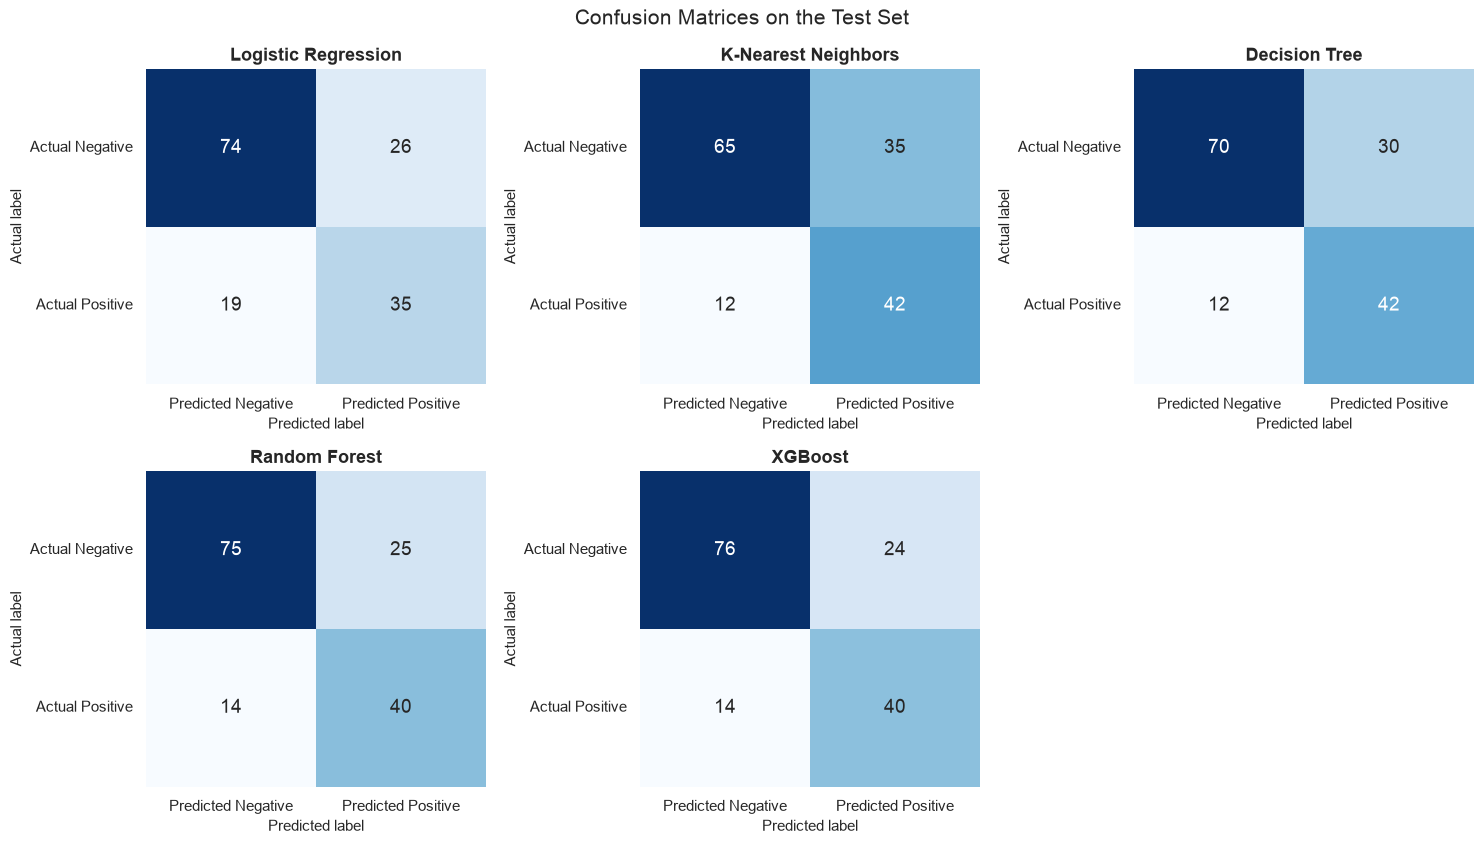

,Model,TP,TN,FP,FN,Recall,Specificity
0,XGBoost,40,76,24,14,0.741,0.76
1,Logistic Regression,35,74,26,19,0.648,0.74
2,Random Forest,40,75,25,14,0.741,0.75
3,K-Nearest Neighbors,42,65,35,12,0.778,0.65
4,Decision Tree,42,70,30,12,0.778,0.70


In [57]:
plot_confusion_matrices(models, X_test, y_test, save_path=FIG_DIR / "13_confusion_matrices.png")
results[["Model", "TP", "TN", "FP", "FN", "Recall", "Specificity"]].round(3)

**Reading the matrices.** The test set contains 54 diabetic and 100 non-diabetic patients. Decision Tree and KNN miss the fewest diabetic patients (12 FN each), but they also raise the most false alarms (30 and 35 FP). Random Forest and XGBoost miss 14 diabetic patients while producing fewer false alarms (25 and 24 FP). Logistic Regression misses the most diabetic patients (19 FN). This illustrates the **trade-off between recall and precision/specificity**: a model that flags more people catches more true cases but also produces more false positives.

#### ROC curves – Dataset 1

The **ROC curve** plots the true-positive rate (recall) against the false-positive rate as the decision threshold moves from 1 to 0. A model that ranks patients perfectly reaches the top-left corner; random guessing follows the diagonal.

**ROC-AUC** (area under the curve) can be read as: *the probability that the model gives a randomly chosen diabetic patient a higher risk score than a randomly chosen non-diabetic patient.* 0.5 = random, 1.0 = perfect ranking. Because it does not depend on a single threshold, ROC-AUC is a good overall measure of how well a model separates the two classes.

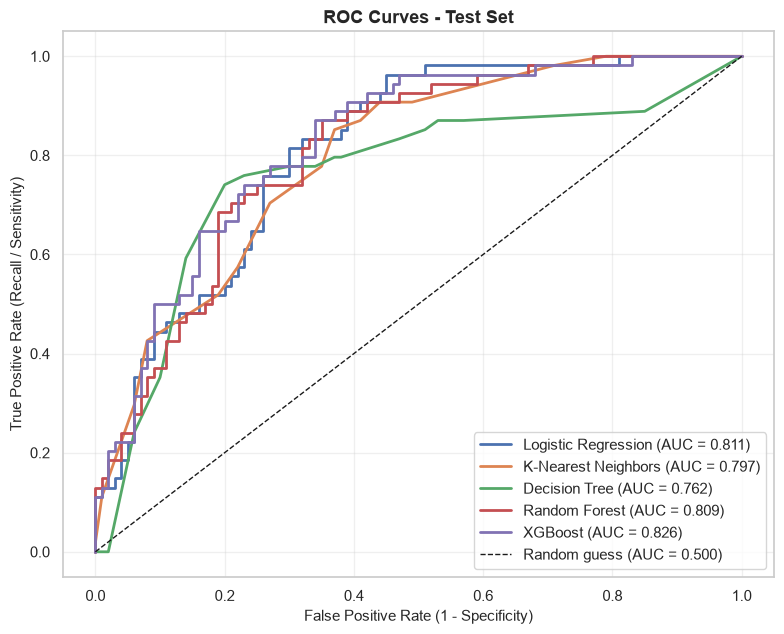

In [58]:
plot_roc_curves(models, X_test, y_test, save_path=FIG_DIR / "14_roc_curves.png")

All five models are far above the random baseline. XGBoost, Logistic Regression and Random Forest have very similar test AUCs (about 0.81–0.83) and nearly overlapping curves. The single Decision Tree has the lowest AUC, which is expected because one shallow tree produces only a few distinct probability values.

#### Model comparison and selection – Dataset 1

First, which model is best on each individual metric (test set):

In [59]:
best_table = best_per_metric(results)
best_table

,Metric,Best model,Value
0,Accuracy,XGBoost,0.7532
1,Precision,XGBoost,0.6250
2,Recall,K-Nearest Neighbors,0.7778
3,F1,XGBoost,0.6780
4,ROC-AUC,XGBoost,0.8263


**No single model wins every metric**, so the final model should not be chosen on accuracy alone. Accuracy is especially misleading with imbalanced classes.

**Selection criteria.** The test set has only 154 patients, so one or two predictions can change a metric noticeably. To make a fair and stable choice:

1. **Screening requirement (recall).** Because missed diabetic cases are the costliest error in screening, a candidate must reach **recall ≥ 0.70 in both cross-validation and the test set**.
2. **Balanced overall performance.** Among the eligible models, choose the highest **overall score**: the mean of all five metrics (Accuracy, Precision, Recall, F1, ROC-AUC), averaged over **cross-validation (training data)** and the **hold-out test set**. Giving equal weight to the two evaluations rewards models that perform consistently instead of being lucky on one split.

No hyperparameters were changed based on the test set. The test set is used only to compare the five pre-defined pipelines.

In [60]:
cv_metric_map = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}
selection = pd.DataFrame({
    "Model": results["Model"],
    "Test mean (5 metrics)": results[main_metrics].mean(axis=1).values,
    "CV mean (5 metrics)": [cv_results.loc[m, [f"CV {v} mean" for v in cv_metric_map.values()]].mean()
                            for m in results["Model"]],
    "Test Recall": results["Recall"].values,
    "CV Recall": [cv_results.loc[m, "CV recall mean"] for m in results["Model"]],
})
selection["Overall score"] = selection[["Test mean (5 metrics)", "CV mean (5 metrics)"]].mean(axis=1)
selection["Recall >= 0.70 (CV & test)"] = (selection[["Test Recall", "CV Recall"]].min(axis=1) >= 0.70)
selection = selection.sort_values("Overall score", ascending=False).reset_index(drop=True)

eligible = selection[selection["Recall >= 0.70 (CV & test)"]]
FINAL_MODEL_NAME = (eligible if len(eligible) else selection).iloc[0]["Model"]
final_model = models[FINAL_MODEL_NAME]

print("Selected final model:", FINAL_MODEL_NAME)
selection.round(4)

Selected final model: Random Forest


,Model,Test mean (5 metrics),CV mean (5 metrics),Test Recall,CV Recall,Overall score,Recall >= 0.70 (CV & test)
0,Random Forest,0.7169,0.7374,0.7407,0.7148,0.7272,True
1,XGBoost,0.7246,0.7096,0.7407,0.6866,0.7171,False
2,K-Nearest Neighbors,0.6913,0.7196,0.7778,0.7898,0.7054,True
3,Logistic Regression,0.6699,0.7372,0.6481,0.7244,0.7036,False
4,Decision Tree,0.7033,0.6637,0.7778,0.6870,0.6835,False


**Result of the selection.**

* **Random Forest** has the highest overall score and meets the recall requirement in both cross-validation and the test set. It ranks first or second on most metrics in *both* evaluations, which makes it the most consistent model.
* **XGBoost** has the best test ROC-AUC, accuracy, precision and F1, but its cross-validated recall is below 0.70, so its strong test result is less consistent across folds.
* **Logistic Regression** has the best cross-validated ROC-AUC, but its test recall is the lowest of all models (it missed 19 of 54 diabetic patients).
* **KNN** and the **Decision Tree** achieve high recall, but with clearly lower precision and specificity, i.e. many false alarms.

**Random Forest is therefore chosen as the final model**: it balances high recall with good precision and ROC-AUC, and its performance is stable across cross-validation and the test set. The margins between the top models are small, and with a different random split their order could change. This uncertainty is discussed in the limitations.

#### Final model – Dataset 1

The final model is the **Random Forest pipeline** (median imputation → standard scaling → SMOTE → Random Forest with 300 trees). Its performance on the held-out test set:

In [61]:
final_row = results.set_index("Model").loc[FINAL_MODEL_NAME]
final_cv = cv_results.loc[FINAL_MODEL_NAME]

print("=" * 62)
print(f"  FINAL MODEL: {FINAL_MODEL_NAME}")
print("=" * 62)
for m in main_metrics + ["Specificity"]:
    print(f"  {m:<12} (test) : {final_row[m]:.4f}")
print("-" * 62)
print(f"  Cross-validated ROC-AUC (train): {final_cv['CV roc_auc mean']:.4f} ± {final_cv['CV roc_auc std']:.4f}")
print(f"  Cross-validated Recall  (train): {final_cv['CV recall mean']:.4f} ± {final_cv['CV recall std']:.4f}")
print(f"  Confusion matrix (test): TP={int(final_row['TP'])}  TN={int(final_row['TN'])}  FP={int(final_row['FP'])}  FN={int(final_row['FN'])}")
print("=" * 62)

  FINAL MODEL: Random Forest
  Accuracy     (test) : 0.7468
  Precision    (test) : 0.6154
  Recall       (test) : 0.7407
  F1           (test) : 0.6723
  ROC-AUC      (test) : 0.8094
  Specificity  (test) : 0.7500
--------------------------------------------------------------
  Cross-validated ROC-AUC (train): 0.8290 ± 0.0253
  Cross-validated Recall  (train): 0.7148 ± 0.0282
  Confusion matrix (test): TP=40  TN=75  FP=25  FN=14


**Why Random Forest?**

* It caught **40 of the 54 diabetic patients** in the test set (recall ≈ 0.74) while keeping precision ≈ 0.62 and specificity ≈ 0.75.
* Its test ROC-AUC (≈ 0.81) and cross-validated ROC-AUC (≈ 0.83) are close, showing **stable** behaviour rather than a lucky split.
* It had the best overall score under the predefined, recall-aware selection rule.
* As an ensemble of trees, it captures non-linear relationships and is less prone to overfitting than a single Decision Tree. Its feature importance and SHAP values are easy to explain.

#### Sample prediction – Dataset 1

`predict_diabetes()` takes the eight measurements for one patient, applies the same cleaning rule (a 0 in Glucose, BloodPressure, SkinThickness, Insulin or BMI is treated as "not measured"), and passes them through the fitted final pipeline. It returns the predicted class and the model's estimated probability of diabetes.

> **Important:** this is an **academic machine-learning demonstration, not a medical diagnosis.** The probability is a model output learned from one historical dataset and is not clinically validated.

In [62]:
def predict_diabetes(Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI,
                     DiabetesPedigreeFunction, Age, model=None, threshold=0.5, verbose=True):
    """Predict diabetes onset for one patient (academic demonstration only).

    Returns a dict with the predicted class (0/1), a readable label and the
    predicted probability of diabetes.
    """
    model = final_model if model is None else model
    values = dict(Pregnancies=Pregnancies, Glucose=Glucose, BloodPressure=BloodPressure,
                  SkinThickness=SkinThickness, Insulin=Insulin, BMI=BMI,
                  DiabetesPedigreeFunction=DiabetesPedigreeFunction, Age=Age)
    if any(v is not None and v < 0 for v in values.values()):
        raise ValueError("Measurements cannot be negative.")
    patient = replace_invalid_zeros(pd.DataFrame([values], columns=FEATURES).astype(float))

    probability = float(model.predict_proba(patient)[0, 1])
    predicted_class = int(probability >= threshold)
    label = "Diabetes likely" if predicted_class == 1 else "Diabetes unlikely"
    if verbose:
        print(f"Predicted class: {label} ({predicted_class})")
        print(f"Probability of diabetes: {probability:.1%}")
        print("Note: academic ML demonstration - NOT a medical diagnosis.")
    return {"predicted_class": predicted_class, "label": label, "probability": probability}


print("Example patient A (high glucose and BMI, older):")
result_a = predict_diabetes(Pregnancies=6, Glucose=168, BloodPressure=74, SkinThickness=35, Insulin=200,
                            BMI=38.2, DiabetesPedigreeFunction=0.85, Age=50)
print("\nExample patient B (normal glucose and BMI, younger):")
result_b = predict_diabetes(Pregnancies=1, Glucose=89, BloodPressure=66, SkinThickness=23, Insulin=94,
                            BMI=24.5, DiabetesPedigreeFunction=0.25, Age=24)
print("\nExample patient C (Insulin and SkinThickness not measured -> recorded as 0):")
result_c = predict_diabetes(Pregnancies=3, Glucose=130, BloodPressure=70, SkinThickness=0, Insulin=0,
                            BMI=32.0, DiabetesPedigreeFunction=0.45, Age=35)

Example patient A (high glucose and BMI, older):
Predicted class: Diabetes likely (1)
Probability of diabetes: 87.2%
Note: academic ML demonstration - NOT a medical diagnosis.

Example patient B (normal glucose and BMI, younger):
Predicted class: Diabetes unlikely (0)
Probability of diabetes: 1.7%
Note: academic ML demonstration - NOT a medical diagnosis.

Example patient C (Insulin and SkinThickness not measured -> recorded as 0):
Predicted class: Diabetes likely (1)
Probability of diabetes: 66.7%
Note: academic ML demonstration - NOT a medical diagnosis.


In [63]:
# Sanity check on five real test patients (NaN = value was recorded as 0, i.e. not measured).
# The raw rows (with their original zeros) are passed to predict_diabetes().
check = X_test.head(5).copy()
check["Actual"] = y_test.head(5).map(OUTCOME_LABELS).values
check["P(diabetes)"] = [predict_diabetes(**row, verbose=False)["probability"]
                        for row in df_raw.loc[X_test.head(5).index, FEATURES].to_dict("records")]
check["Prediction"] = np.where(check["P(diabetes)"] >= 0.5, "Diabetes likely", "Diabetes unlikely")
check.round(3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,P(diabetes),Prediction
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40,No Diabetes,0.780,Diabetes likely
672,10,68.0,106.0,23.0,49.0,35.5,0.285,47,No Diabetes,0.184,Diabetes unlikely
700,2,122.0,76.0,27.0,200.0,35.9,0.483,26,No Diabetes,0.223,Diabetes unlikely
630,7,114.0,64.0,NaN,NaN,27.4,0.732,34,Diabetes,0.403,Diabetes unlikely
81,2,74.0,NaN,NaN,NaN,NaN,0.102,22,No Diabetes,0.134,Diabetes unlikely


### 14.2 Dataset 2 – Early Stage

Here the five Dataset 2 models are evaluated on the 51 test records (35 diabetic, 16 non-diabetic), exactly as for Dataset 1.

In [64]:
print_classification_reports(es_models, es_X_test, es_y_test)

Logistic Regression
              precision    recall  f1-score   support

 No Diabetes      0.667     0.875     0.757        16
    Diabetes      0.933     0.800     0.862        35

    accuracy                          0.824        51
   macro avg      0.800     0.838     0.809        51
weighted avg      0.850     0.824     0.829        51

K-Nearest Neighbors
              precision    recall  f1-score   support

 No Diabetes      0.593     1.000     0.744        16
    Diabetes      1.000     0.686     0.814        35

    accuracy                          0.784        51
   macro avg      0.796     0.843     0.779        51
weighted avg      0.872     0.784     0.792        51

Decision Tree
              precision    recall  f1-score   support

 No Diabetes      0.750     0.938     0.833        16
    Diabetes      0.968     0.857     0.909        35

    accuracy                          0.882        51
   macro avg      0.859     0.897     0.871        51
weighted avg      0.

In [65]:
es_results = evaluate_models(es_models, es_X_test, es_y_test)      # sorted by ROC-AUC (descending)

es_model_comparison = es_results[["Model"] + main_metrics].round(4)
es_model_comparison.to_csv(RESULTS_DIR / "early_stage_model_comparison.csv", index=False)
es_metrics = es_results.merge(es_cv_results.round(4), left_on="Model", right_index=True)
es_metrics.round(4).to_csv(RESULTS_DIR / "early_stage_metrics.csv", index=False)

print("Saved:", (RESULTS_DIR / "early_stage_model_comparison.csv").relative_to(PROJECT_ROOT))
print("Saved:", (RESULTS_DIR / "early_stage_metrics.csv").relative_to(PROJECT_ROOT))
es_model_comparison

Saved: results/early_stage_model_comparison.csv
Saved: results/early_stage_metrics.csv


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.9020,0.9412,0.9143,0.9275,0.9643
1,Decision Tree,0.8824,0.9677,0.8571,0.9091,0.9562
2,XGBoost,0.8824,1.0000,0.8286,0.9062,0.9464
3,K-Nearest Neighbors,0.7843,1.0000,0.6857,0.8136,0.9259
4,Logistic Regression,0.8235,0.9333,0.8000,0.8615,0.9250


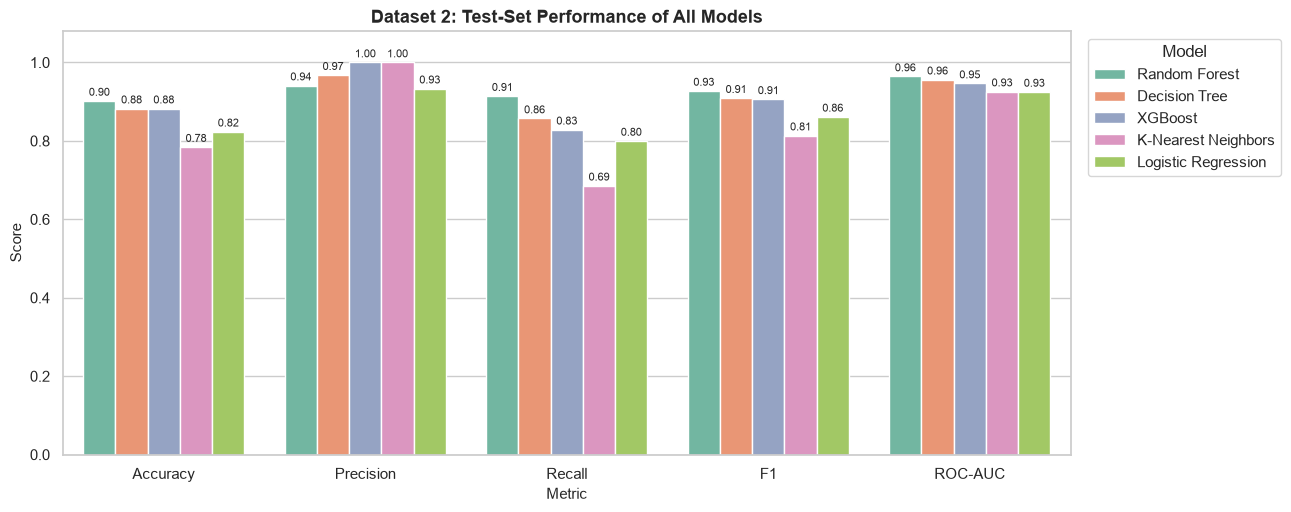

In [66]:
es_plot_df = es_model_comparison.melt(id_vars="Model", value_vars=main_metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=es_plot_df, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Dataset 2: Test-Set Performance of All Models")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "23_es_model_comparison.png")
plt.show()

#### Confusion matrices – Dataset 2

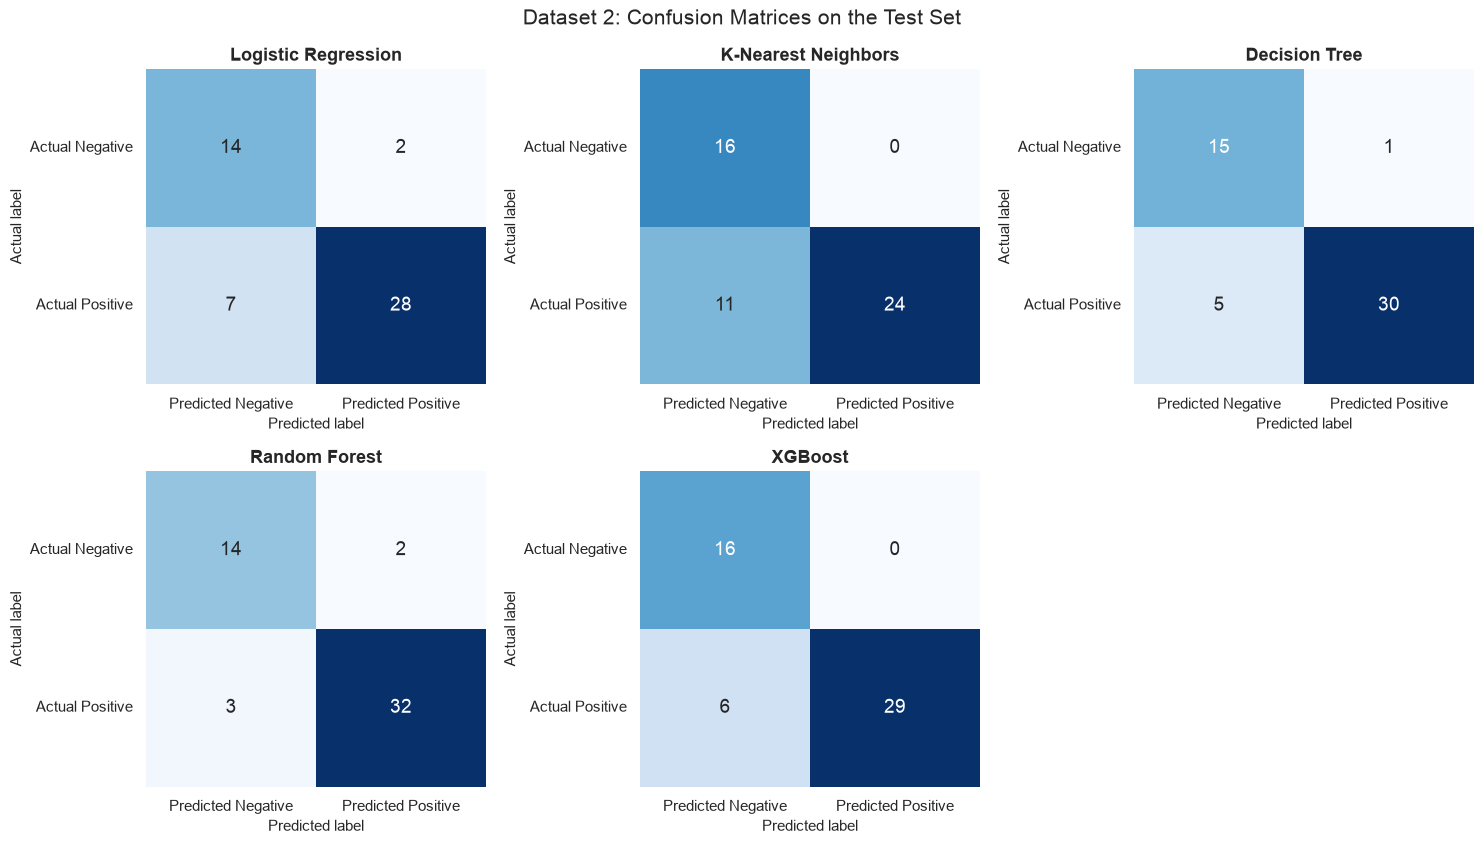

,Model,TP,TN,FP,FN,Recall,Specificity
0,Random Forest,32,14,2,3,0.914,0.875
1,Decision Tree,30,15,1,5,0.857,0.938
2,XGBoost,29,16,0,6,0.829,1.000
3,K-Nearest Neighbors,24,16,0,11,0.686,1.000
4,Logistic Regression,28,14,2,7,0.800,0.875


In [67]:
plot_confusion_matrices(es_models, es_X_test, es_y_test, save_path=FIG_DIR / "24_es_confusion_matrices.png",
                        title="Dataset 2: Confusion Matrices on the Test Set")
es_results[["Model", "TP", "TN", "FP", "FN", "Recall", "Specificity"]].round(3)

**Reading the matrices.** The Dataset 2 test set has 35 diabetic and 16 non-diabetic records. Random Forest misses only **3** diabetic records (FN) with 2 false alarms (FP). XGBoost and KNN raise **no** false alarms at all, but miss 6 and 11 diabetic records respectively, so they are more conservative. As with Dataset 1, the main trade-off is between missing diabetic people (FN) and false alarms (FP).

#### ROC curves – Dataset 2

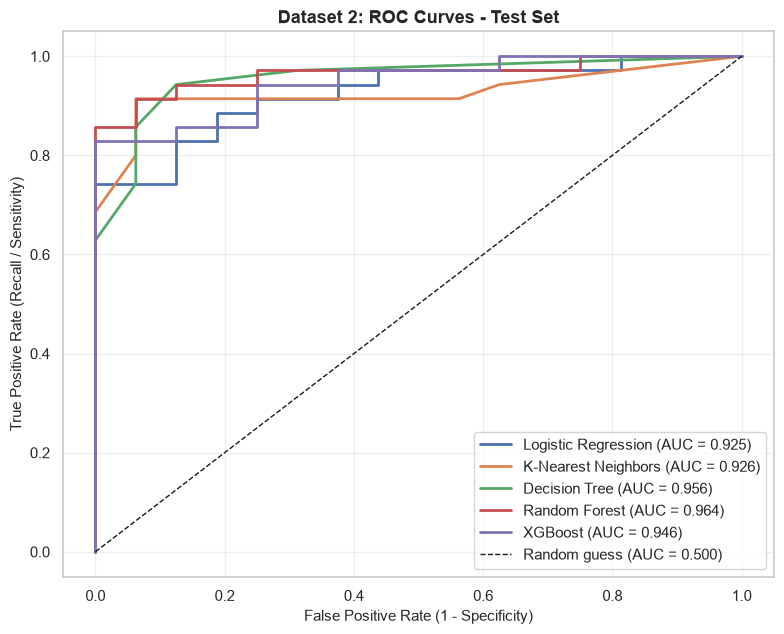

In [68]:
plot_roc_curves(es_models, es_X_test, es_y_test, save_path=FIG_DIR / "25_es_roc_curves.png",
                title="Dataset 2: ROC Curves - Test Set")

All models reach a ROC-AUC above 0.92 on Dataset 2, far above both the random baseline and the Dataset 1 models (0.76–0.83).

#### Model comparison and selection – Dataset 2

Here we apply **exactly the same selection rule** as for Dataset 1: recall ≥ 0.70 in both cross-validation and the test set, then the highest mean of the five metrics averaged over cross-validation and test.

In [69]:
es_best_table = best_per_metric(es_results)
es_selection = pd.DataFrame({
    "Model": es_results["Model"],
    "Test mean (5 metrics)": es_results[main_metrics].mean(axis=1).values,
    "CV mean (5 metrics)": [es_cv_results.loc[m, [f"CV {v} mean" for v in cv_metric_map.values()]].mean()
                            for m in es_results["Model"]],
    "Test Recall": es_results["Recall"].values,
    "CV Recall": [es_cv_results.loc[m, "CV recall mean"] for m in es_results["Model"]],
})
es_selection["Overall score"] = es_selection[["Test mean (5 metrics)", "CV mean (5 metrics)"]].mean(axis=1)
es_selection["Recall >= 0.70 (CV & test)"] = es_selection[["Test Recall", "CV Recall"]].min(axis=1) >= 0.70
es_selection = es_selection.sort_values("Overall score", ascending=False).reset_index(drop=True)

es_eligible = es_selection[es_selection["Recall >= 0.70 (CV & test)"]]
ES_FINAL_MODEL_NAME = (es_eligible if len(es_eligible) else es_selection).iloc[0]["Model"]
es_final_model = es_models[ES_FINAL_MODEL_NAME]

display(es_best_table)
print("Selected final model for Dataset 2:", ES_FINAL_MODEL_NAME)
es_selection.round(4)

,Metric,Best model,Value
0,Accuracy,Random Forest,0.9020
1,Precision,XGBoost,1.0000
2,Recall,Random Forest,0.9143
3,F1,Random Forest,0.9275
4,ROC-AUC,Random Forest,0.9643


Selected final model for Dataset 2: Random Forest


,Model,Test mean (5 metrics),CV mean (5 metrics),Test Recall,CV Recall,Overall score,Recall >= 0.70 (CV & test)
0,Random Forest,0.9298,0.9480,0.9143,0.9421,0.9389,True
1,XGBoost,0.9127,0.9550,0.8286,0.9566,0.9338,True
2,Decision Tree,0.9145,0.9076,0.8571,0.9127,0.9111,True
3,Logistic Regression,0.8687,0.9244,0.8000,0.9130,0.8966,True
4,K-Nearest Neighbors,0.8419,0.9016,0.6857,0.8111,0.8717,False


In [70]:
es_final_row = es_results.set_index("Model").loc[ES_FINAL_MODEL_NAME]
es_final_cv = es_cv_results.loc[ES_FINAL_MODEL_NAME]
print("=" * 62)
print(f"  FINAL MODEL (Dataset 2): {ES_FINAL_MODEL_NAME}")
print("=" * 62)
for m in main_metrics + ["Specificity"]:
    print(f"  {m:<12} (test) : {es_final_row[m]:.4f}")
print("-" * 62)
print(f"  Cross-validated ROC-AUC (train): {es_final_cv['CV roc_auc mean']:.4f} ± {es_final_cv['CV roc_auc std']:.4f}")
print(f"  Cross-validated Recall  (train): {es_final_cv['CV recall mean']:.4f} ± {es_final_cv['CV recall std']:.4f}")
print(f"  Confusion matrix (test): TP={int(es_final_row['TP'])}  TN={int(es_final_row['TN'])}  "
      f"FP={int(es_final_row['FP'])}  FN={int(es_final_row['FN'])}")
print("=" * 62)

  FINAL MODEL (Dataset 2): Random Forest
  Accuracy     (test) : 0.9020
  Precision    (test) : 0.9412
  Recall       (test) : 0.9143
  F1           (test) : 0.9275
  ROC-AUC      (test) : 0.9643
  Specificity  (test) : 0.8750
--------------------------------------------------------------
  Cross-validated ROC-AUC (train): 0.9772 ± 0.0134
  Cross-validated Recall  (train): 0.9421 ± 0.0485
  Confusion matrix (test): TP=32  TN=14  FP=2  FN=3


**Result of the selection (Dataset 2).** **Random Forest** has the highest overall score and meets the recall rule: on the test set it catches **32 of 35** diabetic records (recall 0.914) with precision 0.941 and ROC-AUC 0.964, and its cross-validated ROC-AUC is 0.977. XGBoost is a close second (best cross-validated recall and ROC-AUC, but lower test recall). KNN fails the recall rule (test recall 0.686). With only 51 test records, one record changes recall by almost 3 percentage points, so the small differences between the top three models should not be over-interpreted.

## 15. Comparison of Results

Here the test-set results of both datasets are put into one table. The same five metrics, the same model families and the same selection rule were used for both, so the numbers are directly comparable as *model behaviour*. They are **not** a competition between the datasets, because the populations and features are completely different.

In [71]:
dataset_comparison = pd.concat([
    results.assign(Dataset="1 - Pima").merge(cv_results[["CV roc_auc mean"]], left_on="Model", right_index=True),
    es_results.assign(Dataset="2 - Early Stage").merge(es_cv_results[["CV roc_auc mean"]], left_on="Model", right_index=True),
])
dataset_comparison["Final model"] = np.where(
    ((dataset_comparison["Dataset"] == "1 - Pima") & (dataset_comparison["Model"] == FINAL_MODEL_NAME)) |
    ((dataset_comparison["Dataset"] == "2 - Early Stage") & (dataset_comparison["Model"] == ES_FINAL_MODEL_NAME)), "yes", "")
dataset_comparison = dataset_comparison[["Dataset", "Model"] + main_metrics + ["CV roc_auc mean", "Final model"]]
dataset_comparison = dataset_comparison.rename(columns={"CV roc_auc mean": "CV ROC-AUC"}).round(4).reset_index(drop=True)
dataset_comparison.to_csv(RESULTS_DIR / "dataset_comparison.csv", index=False)
print("Saved:", (RESULTS_DIR / "dataset_comparison.csv").relative_to(PROJECT_ROOT))
dataset_comparison

Saved: results/dataset_comparison.csv


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC,Final model
0,1 - Pima,XGBoost,0.7532,0.6250,0.7407,0.6780,0.8263,0.8217,
1,1 - Pima,Logistic Regression,0.7078,0.5738,0.6481,0.6087,0.8113,0.8427,
2,1 - Pima,Random Forest,0.7468,0.6154,0.7407,0.6723,0.8094,0.8290,yes
3,1 - Pima,K-Nearest Neighbors,0.6948,0.5455,0.7778,0.6412,0.7974,0.8196,
4,1 - Pima,Decision Tree,0.7273,0.5833,0.7778,0.6667,0.7616,0.7617,
5,2 - Early Stage,Random Forest,0.9020,0.9412,0.9143,0.9275,0.9643,0.9772,yes
6,2 - Early Stage,Decision Tree,0.8824,0.9677,0.8571,0.9091,0.9562,0.9004,
7,2 - Early Stage,XGBoost,0.8824,1.0000,0.8286,0.9062,0.9464,0.9802,
8,2 - Early Stage,K-Nearest Neighbors,0.7843,1.0000,0.6857,0.8136,0.9259,0.9657,
9,2 - Early Stage,Logistic Regression,0.8235,0.9333,0.8000,0.8615,0.9250,0.9721,


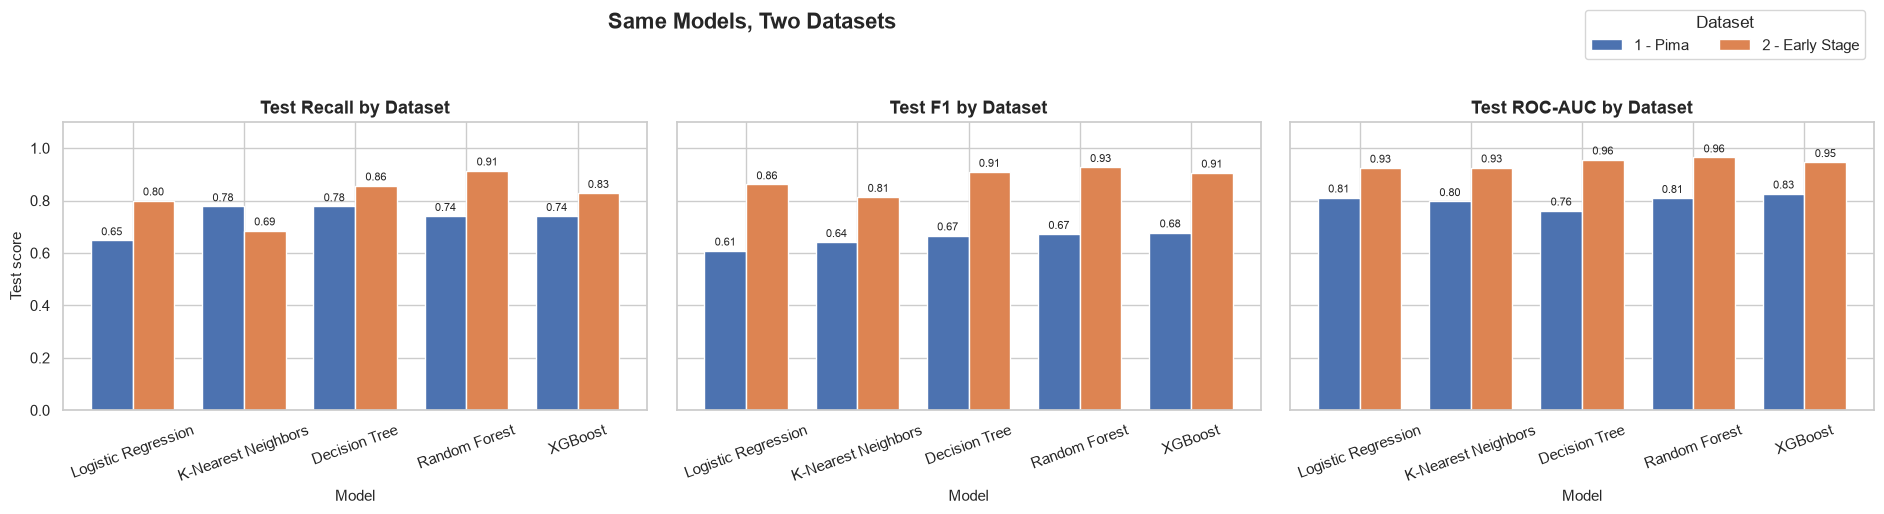

,Accuracy,Precision,Recall,F1,ROC-AUC
Average over the five models,,,,,
1 - Pima,0.726,0.589,0.737,0.653,0.801
2 - Early Stage,0.855,0.968,0.817,0.884,0.944


In [72]:
model_order = list(get_classifiers().keys())
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), sharey=True)
for ax, metric in zip(axes, ["Recall", "F1", "ROC-AUC"]):
    pivot = dataset_comparison.pivot(index="Model", columns="Dataset", values=metric).reindex(model_order)
    pivot.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], width=0.75, rot=20)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
    ax.set_title(f"Test {metric} by Dataset")
    ax.set_xlabel("Model")
    ax.set_ylabel("Test score")
    ax.set_ylim(0, 1.1)
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Dataset", loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Same Models, Two Datasets", fontsize=16, fontweight="bold", x=0.4)
fig.tight_layout(rect=[0, 0, 1, 0.92])
save_fig(fig, "26_dataset_comparison.png")
plt.show()

dataset_comparison.groupby("Dataset")[main_metrics].mean().round(3).rename_axis("Average over the five models")

### 15.1 Why the duplicate check matters (sensitivity analysis)

Here we repeat the Dataset 2 experiment **with the duplicates left in** (all 520 rows, same split settings and models) to show what would have happened without the data-quality step in Section 9.2. This is for comparison only; these numbers are **not** used anywhere else.

In [73]:
es_dup_y, _ = encode_target(es_clean[ES_TARGET])
es_dup_X = es_clean.drop(columns=ES_TARGET)
dX_train, dX_test, dy_train, dy_test = train_test_split(
    es_dup_X, es_dup_y, test_size=0.2, stratify=es_dup_y, random_state=RANDOM_STATE)

row_key = lambda frame: frame.astype(str).agg("|".join, axis=1)
seen_in_train = row_key(dX_test).isin(set(row_key(dX_train)))
print(f"With duplicates: {int(seen_in_train.sum())} of {len(dX_test)} test rows "
      f"({seen_in_train.mean() * 100:.0f} %) have an identical copy in the training set.")

dup_models = train_models(get_es_models(ES_NUMERIC, ES_CATEGORICAL, class_weight=ES_CLASS_WEIGHT,
                                        scale_pos_weight=ES_SCALE_POS_WEIGHT, random_state=RANDOM_STATE),
                          dX_train, dy_train)
dup_results = evaluate_models(dup_models, dX_test, dy_test).set_index("Model")
duplicate_effect = pd.DataFrame({
    "Accuracy (unique records)": es_results.set_index("Model")["Accuracy"],
    "Accuracy (with duplicates)": dup_results["Accuracy"],
    "ROC-AUC (unique records)": es_results.set_index("Model")["ROC-AUC"],
    "ROC-AUC (with duplicates)": dup_results["ROC-AUC"],
}).reindex(es_results["Model"]).round(3)
duplicate_effect

With duplicates: 72 of 104 test rows (69 %) have an identical copy in the training set.
Trained: Logistic Regression
Trained: K-Nearest Neighbors
Trained: Decision Tree
Trained: Random Forest


Trained: XGBoost


,Accuracy (unique records),Accuracy (with duplicates),ROC-AUC (unique records),ROC-AUC (with duplicates)
Model,,,,
Random Forest,0.902,0.971,0.964,0.998
Decision Tree,0.882,0.962,0.956,0.988
XGBoost,0.882,0.971,0.946,1.000
K-Nearest Neighbors,0.784,0.904,0.926,0.995
Logistic Regression,0.824,0.942,0.925,0.991


With the duplicates left in, more than two thirds of the test rows are exact copies of training rows, and every model looks better (Random Forest reaches about 97 % accuracy and a ROC-AUC near 1.0). Part of that "performance" is simply **remembering records seen during training**. Accuracy figures of around 97 % are commonly reported for this dataset; our honest figure on unique records is lower (about 90 % for the final model). This is why the duplicates were removed before splitting.

### 15.2 Discussion

**Which dataset is easier to predict?** Dataset 2 is clearly easier. Averaged over the five models, test ROC-AUC is about 0.94 for Dataset 2 against about 0.80 for Dataset 1, and the final Random Forest reaches 0.90 accuracy and 0.91 recall on Dataset 2 against 0.75 and 0.74 on Dataset 1.

**Which features are important?** In Dataset 1 a single measurement, **Glucose**, dominates, followed by BMI and Age. In Dataset 2 two classic symptoms, **Polyuria** and **Polydipsia**, dominate, followed by Gender and sudden weight loss (details in Section 16).

**Do the models behave consistently across datasets?**
* **Random Forest is selected as the final model for both datasets** by the same rule, and Random Forest and XGBoost are near the top in both.
* In **cross-validated ROC-AUC** (the more stable estimate), the ranking is similar in both datasets: the ensembles and Logistic Regression at the top, the single **Decision Tree at the bottom**. On the small Dataset 2 test set the Decision Tree happens to come second, which shows how much 51 test records can vary.
* **KNN behaves least consistently**: it has the highest test recall on Dataset 1 (0.78) but the lowest on Dataset 2 (0.69). A likely reason is that distances between 0/1 answers are less informative than distances between continuous measurements.
* Logistic Regression is relatively stronger on Dataset 1 (best cross-validated ROC-AUC there), where the signal is smooth and close to linear in glucose.

**Why does performance differ between the datasets?**
* **Different kinds of information.** Dataset 2 records *symptoms* that people with diabetes often already have (excessive urination and thirst). Dataset 1 records measurements of people *before* or around the onset of diabetes, which overlap more between the classes.
* **Different case mix.** Dataset 2 comes from patients of a diabetes hospital (69 % diabetic after removing duplicates); Dataset 1 is a population-based cohort (35 % diabetic).
* **Data quality.** Dataset 1 has many missing clinical values (e.g. 49 % of Insulin); Dataset 2 has none, but had many duplicates.
* **Sample size.** Dataset 2 has only 251 unique records (51 test records), so its test metrics are less precise than Dataset 1's.

**Limitations of comparing the two datasets.** The datasets differ in population (Pima Indian women in the USA vs. hospital patients of both sexes in Bangladesh), time period, collection method (measurements vs. questionnaire), features and class balance. A higher score on Dataset 2 does **not** mean that symptom questionnaires are better screening tools in general, and the two models cannot be applied to each other's data. The comparison only shows how the same modelling approach behaves on two different kinds of diabetes data.

## 16. Feature Importance / SHAP Interpretation

Here we look inside the models: which features do they rely on, and in which direction do the features push the predictions?

### 16.1 Feature importance – Dataset 1

Tree-based models give a built-in **impurity-based feature importance**: how much each feature reduces impurity (Gini / loss) across all splits, normalised to sum to 1. For comparison, the absolute standardised coefficients of Logistic Regression are also shown (comparable because all features were standardised).

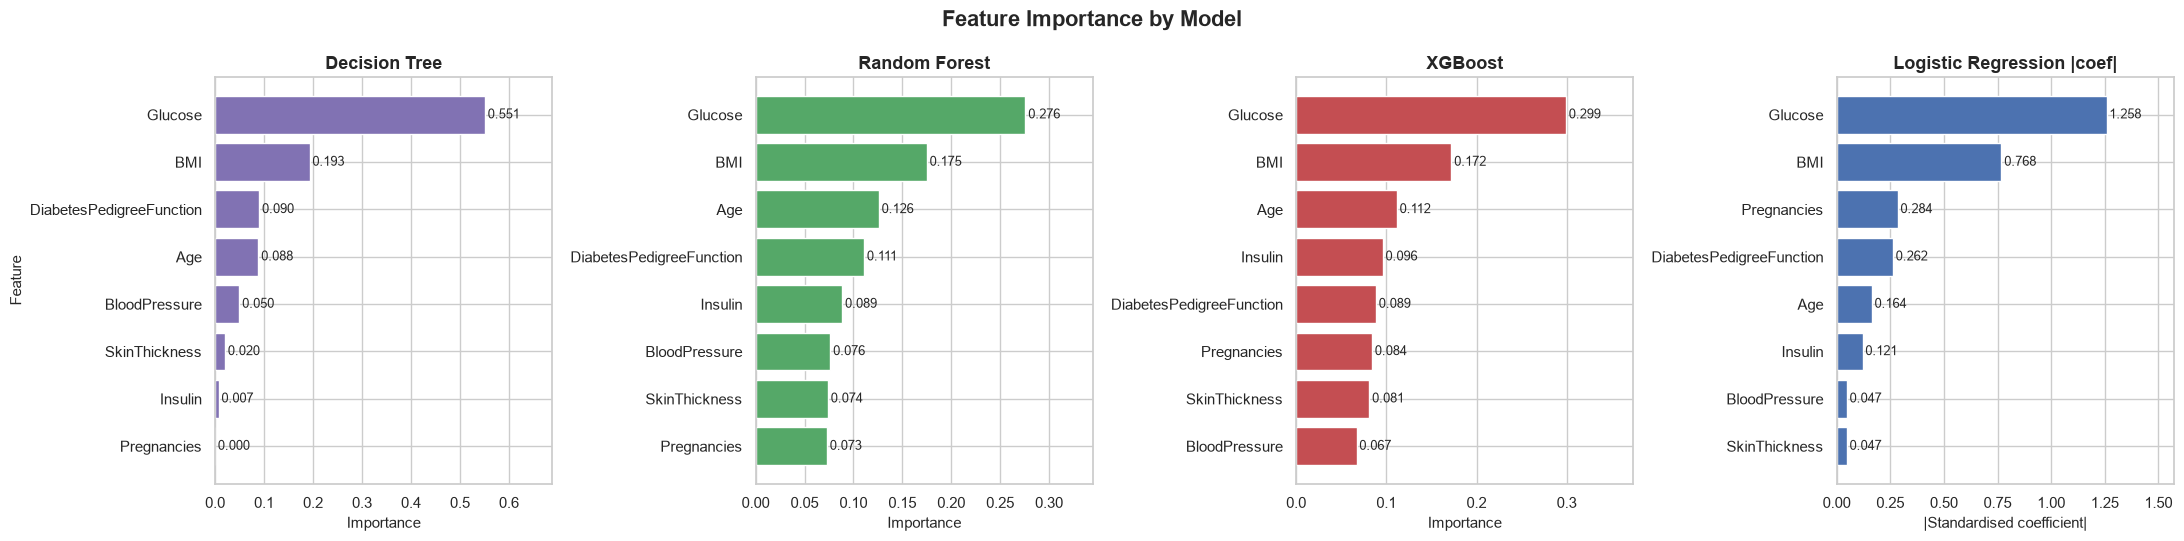

,Decision Tree,Random Forest,XGBoost,Logistic Regression |coef|
Glucose,0.551,0.276,0.299,1.258
BMI,0.193,0.175,0.172,0.768
Age,0.088,0.126,0.112,0.164
DiabetesPedigreeFunction,0.090,0.111,0.089,0.262
Insulin,0.007,0.089,0.096,0.121
BloodPressure,0.050,0.076,0.067,0.047
SkinThickness,0.020,0.074,0.081,0.047
Pregnancies,0.000,0.073,0.084,0.284


In [74]:
importance = {name: models[name].named_steps["model"].feature_importances_
              for name in ["Decision Tree", "Random Forest", "XGBoost"] if name in models}
importance["Logistic Regression |coef|"] = np.abs(models["Logistic Regression"].named_steps["model"].coef_[0])
importance = pd.DataFrame(importance, index=FEATURES)

fig, axes = plt.subplots(1, len(importance.columns), figsize=(5.5 * len(importance.columns), 5.5))
for ax, col, color in zip(axes, importance.columns, ["#8172B3", "#55A868", "#C44E52", "#4C72B0"]):
    s = importance[col].sort_values()
    bars = ax.barh(s.index, s.values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("Importance" if "coef" not in col else "|Standardised coefficient|")
    ax.set_ylabel("Feature" if ax is axes[0] else "")
    ax.set_xlim(0, s.max() * 1.25)
fig.suptitle("Feature Importance by Model", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "15_feature_importance.png")
plt.show()

importance.round(3).sort_values("Random Forest", ascending=False)

**Interpretation.** All four models agree that **Glucose is by far the most influential feature**. In the final Random Forest, it accounts for roughly a quarter of the total importance. **BMI** is consistently second. In the ensemble models, **Age**, **DiabetesPedigreeFunction** and **Insulin** form the next group, while **BloodPressure**, **SkinThickness** and **Pregnancies** contribute the least. Logistic Regression gives Pregnancies a somewhat larger weight. Pregnancies is correlated with Age, so the two features can share the same information. The agreement across very different algorithms makes this ranking more convincing.

Caveats: impurity-based importance can favour continuous features with many distinct values, and it is shared between correlated features (for example Glucose and Insulin). Importance reflects how much the *model relies on* a feature to make predictions. It does **not** prove that the feature causes diabetes.

### 16.2 SHAP interpretation – Dataset 1 final model

**SHAP (SHapley Additive exPlanations)** explains an individual prediction by splitting the difference between the model's prediction and its average prediction into contributions from each feature, based on Shapley values from cooperative game theory.

* A **positive SHAP value** means the feature value pushed this patient's prediction **toward diabetes**.
* A **negative SHAP value** means it pushed the prediction **toward no diabetes**.
* The **mean absolute SHAP value** across patients measures a feature's overall (relative) importance.

SHAP values are computed for the final model on the 154 test patients. The model receives imputed and standardised features. To keep the plots readable, the colour scale uses the imputed values in their **original units**; scaling does not change which values are high or low. If SHAP fails (e.g. version incompatibility), the cell falls back to **permutation importance** so the notebook still completes.

In [75]:
final_clf = final_model.named_steps["model"]
X_test_imputed = pd.DataFrame(final_model.named_steps["imputer"].transform(X_test), columns=FEATURES)
X_test_model = pd.DataFrame(final_model.named_steps["scaler"].transform(X_test_imputed), columns=FEATURES)

SHAP_OK = False
try:
    import shap
    if hasattr(final_clf, "feature_importances_"):            # tree models
        explainer = shap.TreeExplainer(final_clf)
        sv = explainer.shap_values(X_test_model)
    else:                                                     # linear / other models
        background = shap.sample(X_test_model, 50, random_state=RANDOM_STATE)
        explainer = shap.Explainer(final_clf.predict_proba, background)
        sv = explainer(X_test_model).values
    # Normalise output shape to (n_samples, n_features) for the positive class
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    shap_values = sv
    SHAP_OK = True
    print(f"SHAP {shap.__version__}: computed values with shape {shap_values.shape} for {FINAL_MODEL_NAME}")
except Exception as exc:
    print("SHAP could not be computed, using permutation importance instead. Reason:", exc)

SHAP 0.53.0: computed values with shape (154, 8) for Random Forest


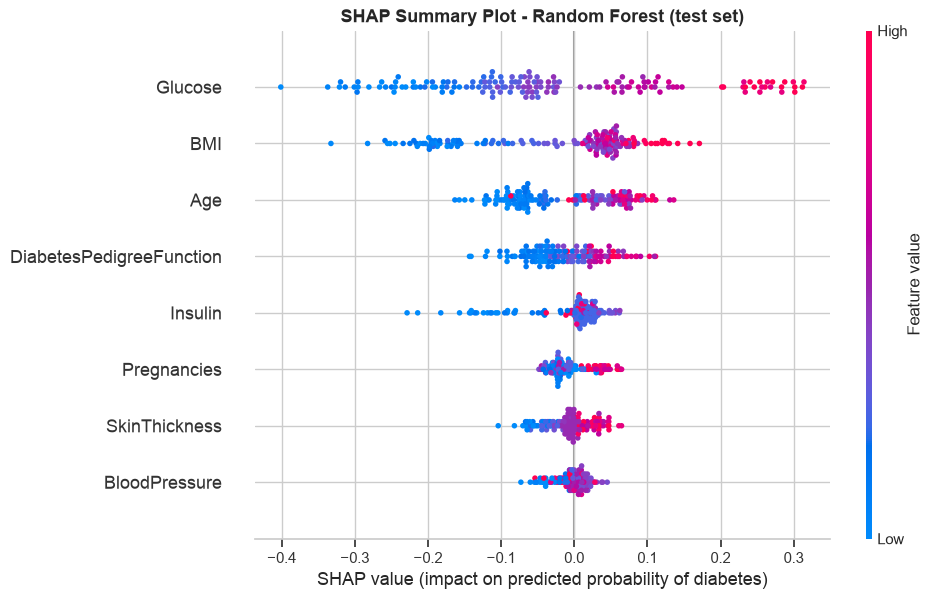

In [76]:
if SHAP_OK:
    shap.summary_plot(shap_values, X_test_imputed, feature_names=FEATURES, show=False, plot_size=(10, 6))
    fig = plt.gcf()
    plt.title(f"SHAP Summary Plot - {FINAL_MODEL_NAME} (test set)", fontsize=13, fontweight="bold")
    plt.xlabel("SHAP value (impact on predicted probability of diabetes)")
    save_fig(fig, "16_shap_summary.png")
    plt.show()
else:
    perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                  random_state=RANDOM_STATE)
    s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(s.index, s.values, color="#55A868")
    ax.set_title(f"Permutation Importance (fallback) - {FINAL_MODEL_NAME}")
    ax.set_xlabel("Mean decrease in ROC-AUC when the feature is shuffled")
    ax.set_ylabel("Feature")
    save_fig(fig, "16_shap_summary.png")
    plt.show()

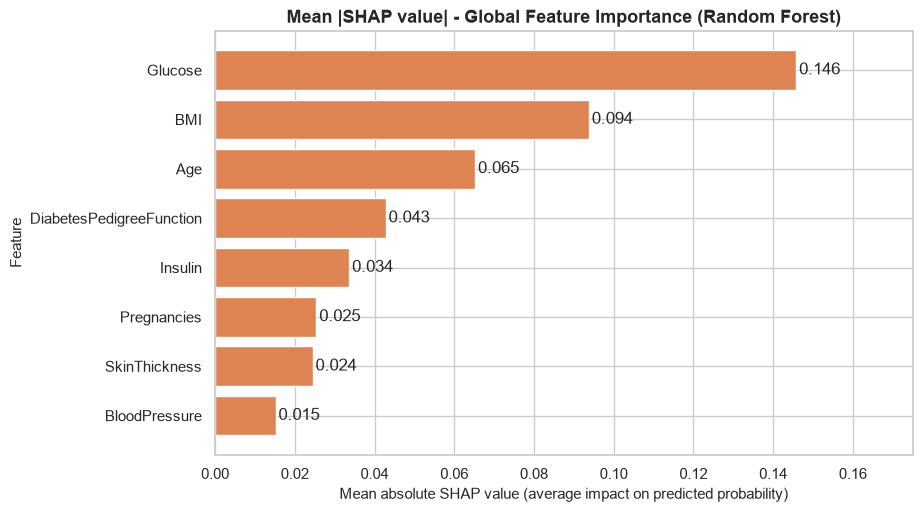

,Mean |SHAP|,"Corr(feature value, SHAP)",Higher value pushes prediction
Glucose,0.146,0.955,toward Diabetes
BMI,0.094,0.837,toward Diabetes
Age,0.065,0.733,toward Diabetes
DiabetesPedigreeFunction,0.043,0.682,toward Diabetes
Insulin,0.034,0.237,toward Diabetes
Pregnancies,0.025,0.635,toward Diabetes
SkinThickness,0.024,0.778,toward Diabetes
BloodPressure,0.015,0.255,toward Diabetes


In [77]:
if SHAP_OK:
    mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.barh(mean_abs.index, mean_abs.values, color="#DD8452")
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_title(f"Mean |SHAP value| - Global Feature Importance ({FINAL_MODEL_NAME})")
    ax.set_xlabel("Mean absolute SHAP value (average impact on predicted probability)")
    ax.set_ylabel("Feature")
    ax.set_xlim(0, mean_abs.max() * 1.2)
    save_fig(fig, "17_shap_importance_bar.png")
    plt.show()

    # Direction: does a higher feature value tend to push toward diabetes (+) or away (-)?
    direction = [np.corrcoef(X_test_imputed[f], shap_values[:, i])[0, 1] for i, f in enumerate(FEATURES)]
    shap_table = pd.DataFrame({"Mean |SHAP|": np.abs(shap_values).mean(axis=0),
                               "Corr(feature value, SHAP)": direction}, index=FEATURES)
    shap_table["Higher value pushes prediction"] = np.where(shap_table["Corr(feature value, SHAP)"] > 0,
                                                            "toward Diabetes", "toward No Diabetes")
    display(shap_table.sort_values("Mean |SHAP|", ascending=False).round(3))

**How to read the SHAP summary plot.** Each dot is one test patient. Its horizontal position is the SHAP value (how much that feature moved the predicted probability), and its colour is the feature value (red = high, blue = low).

**Interpretation for the final Random Forest**

* **Glucose** has the largest mean |SHAP| value. High glucose values (red) lie on the positive side and push predictions toward *diabetes*, while low values (blue) push toward *no diabetes*. This matches the EDA.
* **BMI** and **Age** come next. Higher BMI and older age are associated with higher predicted risk.
* **DiabetesPedigreeFunction**, **Pregnancies** and **SkinThickness** have smaller effects in the same direction: higher values tend to raise predicted risk.
* **Insulin** behaves asymmetrically. *Low* insulin values push predictions clearly toward no diabetes, while high values have only a small effect. Many Insulin values were imputed with the training median, which concentrates them near zero SHAP.
* **BloodPressure** has the smallest average impact and no clear direction (red and blue dots are mixed around zero).
* The SHAP ranking broadly agrees with the impurity-based importance in Section 16.1, which increases confidence in the interpretation.

**Caution.** SHAP explains *how this model uses the features*; it does not show that a feature *causes* diabetes. Correlated features (e.g. SkinThickness and BMI) can share or swap credit, and imputed values for Insulin and SkinThickness carry less information than measured values.

### 16.3 Feature importance – Dataset 2

Here we repeat the same analysis for Dataset 2. The models see the **encoded** features, so each Yes/No column appears as one feature, e.g. `Polyuria = Yes` (1 = Yes). For Logistic Regression the absolute coefficients are shown; the sign tells the direction (positive = pushes towards diabetes).

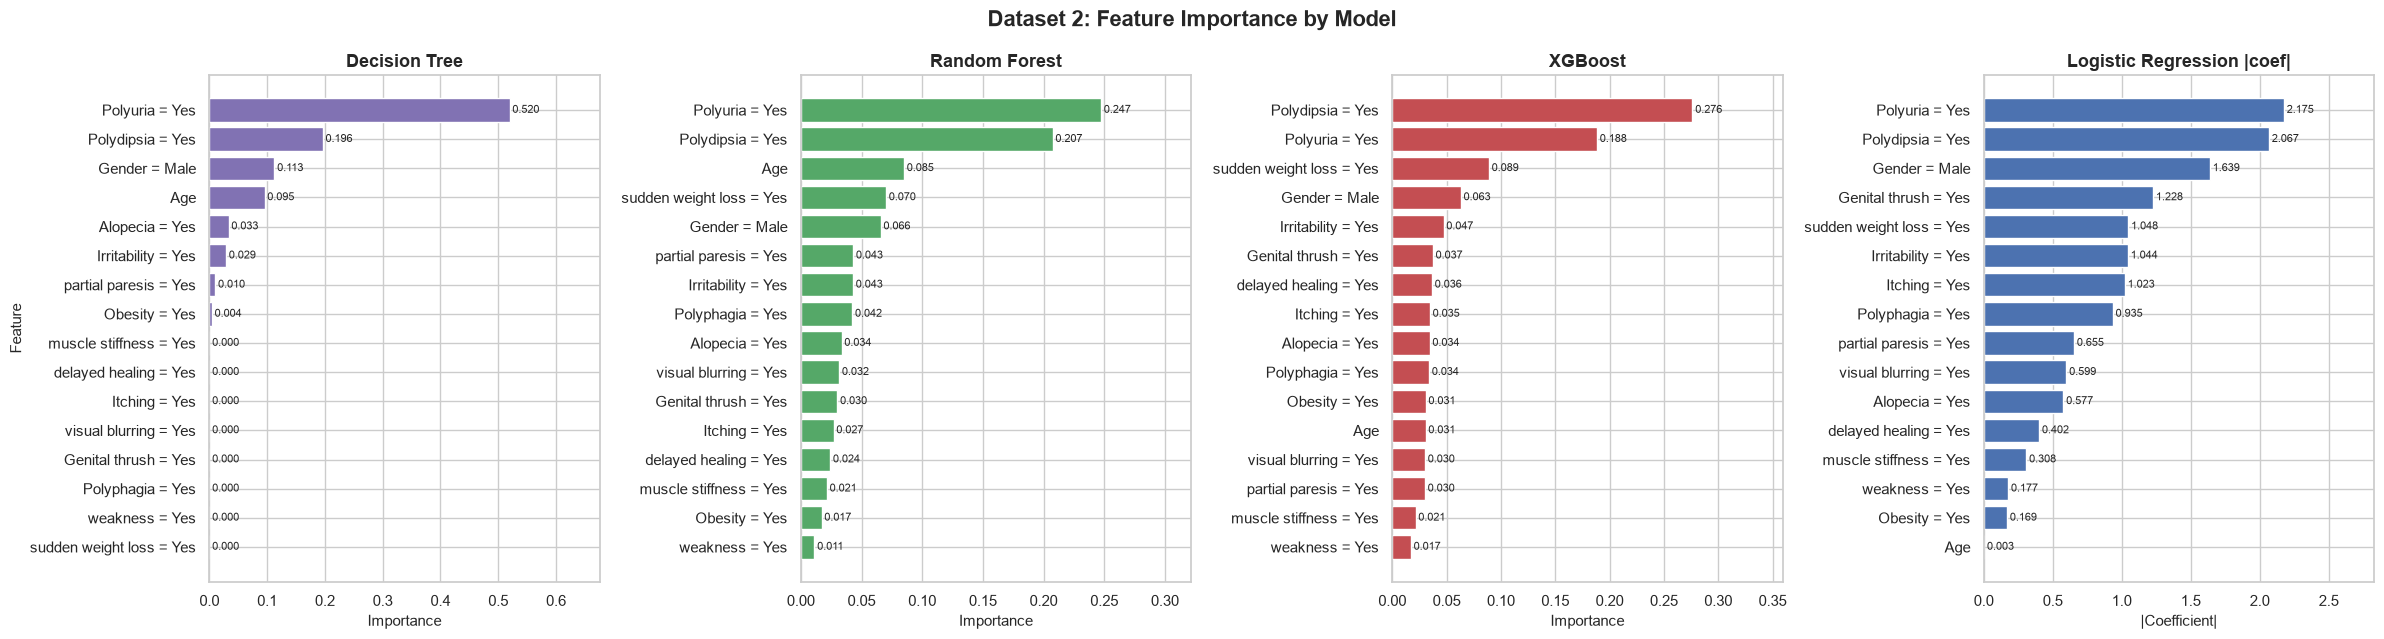

,Decision Tree,Random Forest,XGBoost,Logistic Regression |coef|,LR coefficient (signed)
Polyuria = Yes,0.520,0.247,0.188,2.175,2.175
Polydipsia = Yes,0.196,0.207,0.276,2.067,2.067
Age,0.095,0.085,0.031,0.003,0.003
sudden weight loss = Yes,0.000,0.070,0.089,1.048,1.048
Gender = Male,0.113,0.066,0.063,1.639,-1.639
Irritability = Yes,0.029,0.043,0.047,1.044,1.044
partial paresis = Yes,0.010,0.043,0.030,0.655,0.655
Polyphagia = Yes,0.000,0.042,0.034,0.935,0.935
Alopecia = Yes,0.033,0.034,0.034,0.577,-0.577
visual blurring = Yes,0.000,0.032,0.030,0.599,0.599


In [78]:
es_importance = {name: es_models[name].named_steps["model"].feature_importances_
                 for name in ["Decision Tree", "Random Forest", "XGBoost"] if name in es_models}
es_lr_coef = es_models["Logistic Regression"].named_steps["model"].coef_[0]
es_importance["Logistic Regression |coef|"] = np.abs(es_lr_coef)
es_importance = pd.DataFrame(es_importance, index=ES_FEATURE_NAMES)

fig, axes = plt.subplots(1, len(es_importance.columns), figsize=(6 * len(es_importance.columns), 6.5))
for ax, col, color in zip(axes, es_importance.columns, ["#8172B3", "#55A868", "#C44E52", "#4C72B0"]):
    s = es_importance[col].sort_values()
    bars = ax.barh(s.index, s.values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
    ax.set_title(col)
    ax.set_xlabel("Importance" if "coef" not in col else "|Coefficient|")
    ax.set_ylabel("Feature" if ax is axes[0] else "")
    ax.set_xlim(0, s.max() * 1.3)
fig.suptitle("Dataset 2: Feature Importance by Model", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "27_es_feature_importance.png")
plt.show()

es_importance.assign(**{"LR coefficient (signed)": es_lr_coef}).round(3).sort_values(
    "Random Forest", ascending=False)

**Interpretation (Dataset 2).** All models agree that **Polyuria** and **Polydipsia** are the two most important features; in the Random Forest they account for almost half of the total importance. **Sudden weight loss**, **Gender** and **Irritability** follow. **Age** ranks third in the tree models, but impurity-based importance is known to favour continuous features (Age is the only one here); Logistic Regression and SHAP (below) give it very little weight. The signed logistic-regression coefficients show the direction: most symptoms push towards diabetes, while `Gender = Male` and `Alopecia = Yes` push *away* from it, matching the EDA. As for Dataset 1, importance describes how the models use the features, not medical causation.

### 16.4 SHAP interpretation – Dataset 2 final model

Here SHAP values are computed for the Dataset 2 final model on its 51 test records, exactly as in Section 16.2. For the colour scale, `Age` is shown in years and the other features as 0 (No / Female) or 1 (Yes / Male). If SHAP is unavailable, permutation importance is used instead.

In [79]:
es_final_clf = es_final_model.named_steps["model"]
es_X_test_model = pd.DataFrame(es_final_model.named_steps["preprocess"].transform(es_X_test), columns=ES_FEATURE_NAMES)
es_X_test_display = es_X_test_model.copy()
es_X_test_display["Age"] = es_X_test["Age"].to_numpy()        # colour scale in years

ES_SHAP_OK = False
try:
    import shap
    if hasattr(es_final_clf, "feature_importances_"):           # tree models
        es_sv = shap.TreeExplainer(es_final_clf).shap_values(es_X_test_model)
    else:                                                        # linear / other models
        es_background = shap.sample(es_X_test_model, 30, random_state=RANDOM_STATE)
        es_sv = shap.Explainer(es_final_clf.predict_proba, es_background)(es_X_test_model).values
    if isinstance(es_sv, list):
        es_sv = es_sv[1]
    es_sv = np.asarray(es_sv)
    if es_sv.ndim == 3:
        es_sv = es_sv[:, :, 1]
    es_shap_values = es_sv
    ES_SHAP_OK = True
    print(f"SHAP {shap.__version__}: computed values with shape {es_shap_values.shape} for {ES_FINAL_MODEL_NAME}")
except Exception as exc:
    print("SHAP could not be computed, using permutation importance instead. Reason:", exc)

SHAP 0.53.0: computed values with shape (51, 16) for Random Forest


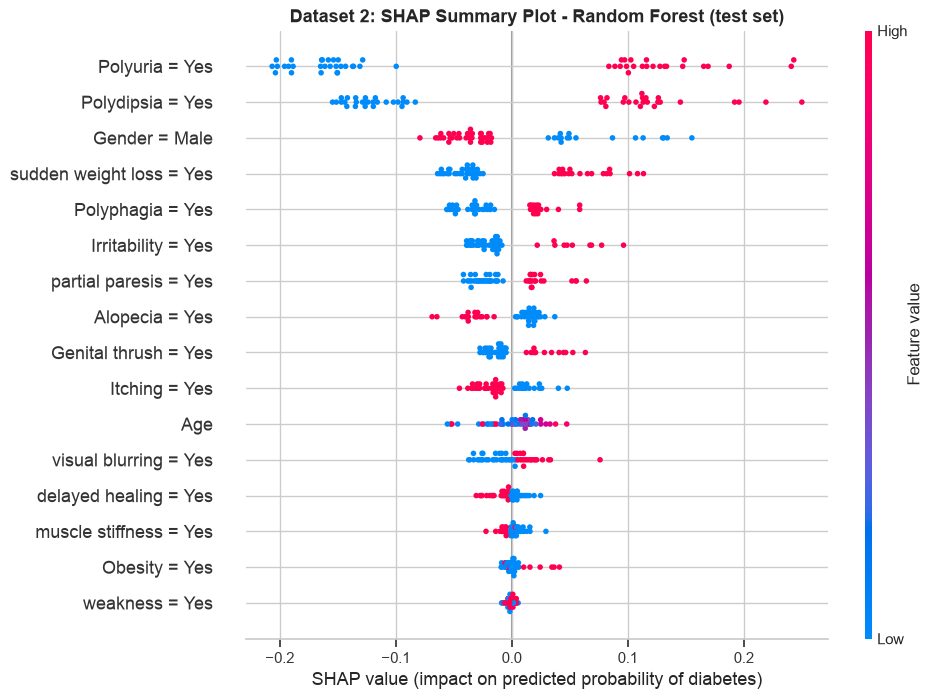

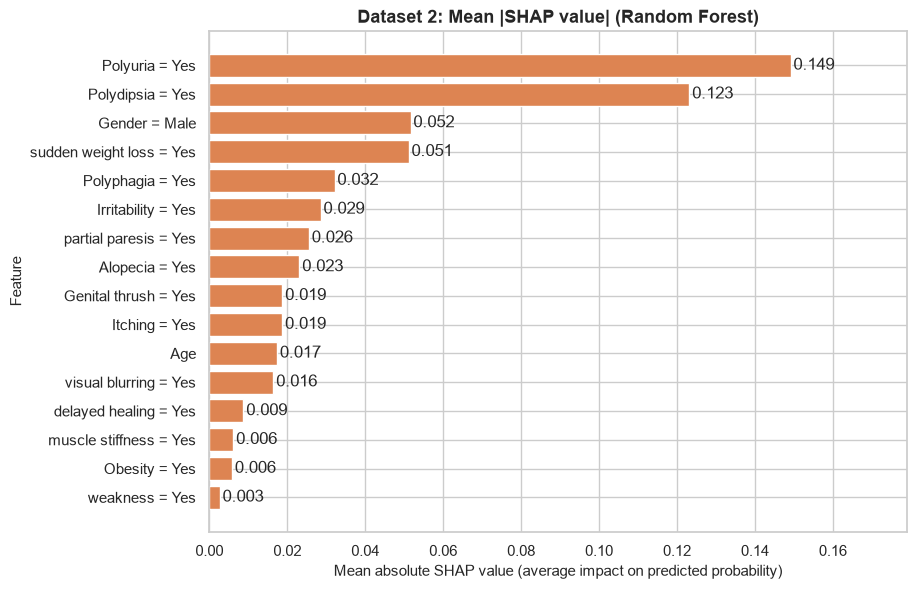

,Mean |SHAP|,"Corr(feature value, SHAP)",Higher value / 'Yes' pushes prediction
Polyuria = Yes,0.149,0.973,toward Diabetes
Polydipsia = Yes,0.123,0.964,toward Diabetes
Gender = Male,0.052,-0.894,toward No Diabetes
sudden weight loss = Yes,0.051,0.949,toward Diabetes
Polyphagia = Yes,0.032,0.923,toward Diabetes
Irritability = Yes,0.029,0.925,toward Diabetes
partial paresis = Yes,0.026,0.899,toward Diabetes
Alopecia = Yes,0.023,-0.933,toward No Diabetes
Genital thrush = Yes,0.019,0.899,toward Diabetes
Itching = Yes,0.019,-0.853,toward No Diabetes


In [80]:
if ES_SHAP_OK:
    shap.summary_plot(es_shap_values, es_X_test_display, feature_names=ES_FEATURE_NAMES, show=False, plot_size=(10, 7))
    fig = plt.gcf()
    plt.title(f"Dataset 2: SHAP Summary Plot - {ES_FINAL_MODEL_NAME} (test set)", fontsize=13, fontweight="bold")
    plt.xlabel("SHAP value (impact on predicted probability of diabetes)")
    save_fig(fig, "28_es_shap_summary.png")
    plt.show()

    es_mean_abs = pd.Series(np.abs(es_shap_values).mean(axis=0), index=ES_FEATURE_NAMES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 6.5))
    bars = ax.barh(es_mean_abs.index, es_mean_abs.values, color="#DD8452")
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_title(f"Dataset 2: Mean |SHAP value| ({ES_FINAL_MODEL_NAME})")
    ax.set_xlabel("Mean absolute SHAP value (average impact on predicted probability)")
    ax.set_ylabel("Feature")
    ax.set_xlim(0, es_mean_abs.max() * 1.2)
    save_fig(fig, "29_es_shap_importance_bar.png")
    plt.show()

    es_direction = [np.corrcoef(es_X_test_display[f], es_shap_values[:, i])[0, 1]
                    if es_X_test_display[f].std() > 0 else np.nan for i, f in enumerate(ES_FEATURE_NAMES)]
    es_shap_table = pd.DataFrame({"Mean |SHAP|": np.abs(es_shap_values).mean(axis=0),
                                  "Corr(feature value, SHAP)": es_direction}, index=ES_FEATURE_NAMES)
    es_shap_table["Higher value / 'Yes' pushes prediction"] = np.where(
        es_shap_table["Corr(feature value, SHAP)"] > 0, "toward Diabetes", "toward No Diabetes")
    display(es_shap_table.sort_values("Mean |SHAP|", ascending=False).round(3))
else:
    perm = permutation_importance(es_final_model, es_X_test, es_y_test, scoring="roc_auc", n_repeats=20,
                                  random_state=RANDOM_STATE)
    s = pd.Series(perm.importances_mean, index=es_X_test.columns).sort_values()
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.barh(s.index, s.values, color="#55A868")
    ax.set_title(f"Dataset 2: Permutation Importance (fallback) - {ES_FINAL_MODEL_NAME}")
    ax.set_xlabel("Mean decrease in ROC-AUC when the feature is shuffled")
    ax.set_ylabel("Feature")
    save_fig(fig, "28_es_shap_summary.png")
    plt.show()

**Interpretation (Dataset 2).**

* **Polyuria = Yes** and **Polydipsia = Yes** have by far the largest SHAP values: answering "Yes" pushes the predicted probability of diabetes clearly up, answering "No" pushes it down.
* **Gender = Male** pushes predictions *towards no diabetes* in this sample, and **sudden weight loss**, **Polyphagia**, **Irritability** and **partial paresis** push towards diabetes.
* **Alopecia = Yes** pushes slightly towards *no* diabetes, consistent with the EDA.
* `Age` has only a small SHAP value, confirming that its high impurity importance mainly reflects that measure's bias towards continuous features.
* Otherwise the SHAP ranking broadly agrees with the impurity importance and the logistic-regression coefficients.

**Across both datasets**, the final model relies mainly on one or two features that are directly linked to high blood sugar: **Glucose** in Dataset 1, **Polyuria and Polydipsia** in Dataset 2. SHAP explains how the models use the data; it does not prove medical causality.

## 17. Overall Findings

| | Dataset 1 – Pima | Dataset 2 – Early Stage |
|---|---|---|
| **Records used** | 768 patients | 251 unique records (269 duplicates removed) |
| **Main data-quality issue** | Invalid zeros (Insulin 49 %, SkinThickness 30 % missing) | 52 % exact duplicate rows |
| **Class balance** | 35 % diabetic (minority) | 69 % diabetic (majority) |
| **Imbalance handling** | SMOTE inside the pipeline (training data only) | None; class weights lowered recall in cross-validation |
| **Final model (same rule)** | Random Forest | Random Forest |
| **Final model – test accuracy / recall / ROC-AUC** | 0.747 / 0.741 / 0.809 | 0.902 / 0.914 / 0.964 |
| **Most important features** | Glucose, BMI, Age, Diabetes Pedigree Function | Polyuria, Polydipsia, Gender, sudden weight loss |

1. **The same leak-free methodology works on both datasets**, but each dataset needed its own data-quality step (invalid zeros vs. duplicates) and its own imbalance decision.
2. **Dataset 2 is easier to predict** (ROC-AUC about 0.94 vs 0.80 on average), mainly because its symptoms are strongly linked to the class, whereas Pima's clinical measurements overlap more between the classes.
3. **Random Forest is the most consistent model**: it is selected by the same recall-aware rule on both datasets.
4. **Data quality can change conclusions.** Leaving Dataset 2's duplicates in would have inflated accuracy to about 97 %.
5. **Interpretation is consistent**: in both datasets the most important features are those most directly related to high blood sugar.

## 18. Conclusion

* **Problem.** We built supervised binary classifiers that estimate whether a person is likely to have diabetes, as an academic example of screening-support models.
* **Datasets.** Dataset 1: Pima Indians Diabetes (768 patients, 8 clinical measurements, 35 % diabetic). Dataset 2: UCI Early Stage Diabetes Risk Prediction (520 questionnaire records, 251 unique, 16 symptom/demographic features). The datasets were **not merged**; each was analysed separately.
* **Preprocessing.** Dataset 1: impossible zeros treated as missing, then median imputation, scaling and SMOTE inside a pipeline. Dataset 2: automatic target detection, text clean-up, duplicate removal, then imputation, scaling and one-hot encoding inside a pipeline. In both, the stratified train/test split came **before** any step that learns from data, so there is no leakage.
* **Models compared.** Logistic Regression, KNN, Decision Tree, Random Forest and XGBoost on both datasets, evaluated with 5-fold cross-validation on the training data and on the hold-out test sets.
* **Best models.** **Random Forest** on both datasets, selected with the same recall-aware rule. Dataset 1: accuracy 0.747, recall 0.741, ROC-AUC 0.809. Dataset 2: accuracy 0.902, recall 0.914, ROC-AUC 0.964.
* **Important features.** Glucose (Dataset 1); Polyuria and Polydipsia (Dataset 2). Feature importance, SHAP, coefficients and EDA agree.
* **Main message.** Performance depends strongly on what information a dataset contains and on careful data-quality checks; the same honest evaluation method makes the two results comparable.

### 18.1 Future Scope

1. **Larger and more diverse datasets.** Include men, different ethnicities and age groups, and more recent data (e.g. national health surveys). For Dataset 2, a larger questionnaire sample without duplicate records.
2. **Combining information types.** A dataset that records both clinical measurements and symptoms for the same people would allow a single model to use both.
3. **External validation.** Test the model on data from a different hospital or population before drawing any practical conclusion.
4. **Hyperparameter optimisation.** Use `GridSearchCV` / `RandomizedSearchCV` or nested cross-validation on training data only.
5. **Explainable AI.** Show per-patient SHAP explanations (waterfall plots) so a clinician can see *why* a patient was flagged.
6. **Probability calibration.** Use Platt scaling or isotonic regression so that a predicted "70 %" truly corresponds to about a 70 % observed rate.
7. **Threshold selection.** Choose a decision threshold that reflects the relative costs of false negatives and false positives.
8. **Additional clinical features.** HbA1c, family history details, physical activity and diet could improve predictions.
9. **Deployment as a screening-support tool.** A simple web form backed by the saved pipeline, used only to support (not replace) clinical judgement.
10. **Monitoring model drift.** After deployment, track input distributions and performance over time and retrain when they change.

### 18.2 Final KDD Mapping

| KDD Stage | Dataset 1 – Pima | Dataset 2 – Early Stage | Section |
|---|---|---|---|
| Problem Definition | Diabetes (Outcome 0/1) from clinical measurements | Diabetes (class Positive/Negative) from symptoms | 1–3 |
| Data Selection | Pima Indians Diabetes Dataset (768 × 9) | UCI Early Stage Diabetes Risk Prediction (520 × 17) | 4–5 |
| Data Understanding | Shape, types, statistics, class balance | Column inspection, automatic target detection, duplicates | 6 |
| EDA | Distributions, boxplots, correlations, pairplot | Symptom prevalence, gender, age, association heatmap | 7–8 |
| Data Cleaning | Invalid zeros → NaN | Unknown tokens → NaN, duplicates removed | 9 |
| Data Transformation | Split, median imputation, scaling, SMOTE (train only) | Split, imputation, scaling, one-hot encoding (train only) | 10–11 |
| Modeling | LR, KNN, DT, RF, XGBoost | LR, KNN, DT, RF, XGBoost | 12–13 |
| Evaluation | Accuracy, Precision, Recall, F1, ROC-AUC, CV | Same metrics, same selection rule | 14–15 |
| Interpretation | Feature importance + SHAP | Feature importance + SHAP | 16 |
| Knowledge Discovery | Glucose dominates; Random Forest selected | Polyuria & Polydipsia dominate; Random Forest selected | 17–18 |

In [81]:
generated = sorted(p.name for p in FIG_DIR.glob("*.png"))
print(f"{len(generated)} figures saved in results/figures/:")
for name in generated:
    print("  -", name)
print("\nResult files   :", [p.name for p in sorted(RESULTS_DIR.glob("*.csv"))])
print("Processed data :", [p.name for p in sorted(PROCESSED_DIR.glob("*.csv"))])

29 figures saved in results/figures/:
  - 01_kdd_workflow.png
  - 02_invalid_zeros.png
  - 03_outcome_distribution.png
  - 04_feature_distributions.png
  - 05_glucose_by_outcome.png
  - 06_bmi_by_outcome.png
  - 07_age_by_outcome.png
  - 08_boxplots_by_outcome.png
  - 09_correlation_heatmap.png
  - 10_pairplot_selected_features.png
  - 11_smote_class_distribution.png
  - 12_model_comparison.png
  - 13_confusion_matrices.png
  - 14_roc_curves.png
  - 15_feature_importance.png
  - 16_shap_summary.png
  - 17_shap_importance_bar.png
  - 18_es_class_distribution.png
  - 19_es_age_by_class.png
  - 20_es_gender_by_class.png
  - 21_es_symptom_prevalence.png
  - 22_es_association_heatmap.png
  - 23_es_model_comparison.png
  - 24_es_confusion_matrices.png
  - 25_es_roc_curves.png
  - 26_dataset_comparison.png
  - 27_es_feature_importance.png
  - 28_es_shap_summary.png
  - 29_es_shap_importance_bar.png

Result files   : ['dataset_comparison.csv', 'early_stage_metrics.csv', 'early_stage_model_comp

## 19. Limitations

**Dataset 1 – Pima**

* **Small dataset.** 768 patients (154 in the test set) is small. Metrics computed on 154 patients have wide uncertainty: one patient changes test recall by almost 2 percentage points.
* **Narrow demographics.** All patients are Pima Indian women aged 21 or older. The model may not generalise to men, other ethnic groups or younger people.
* **Historical data.** The data were collected decades ago, using diagnostic criteria and measurement practices of that time.
* **Potential sampling bias.** The cohort comes from a specific population study and is not a random sample of any general population.
* **Measurement quality and missing values.** Nearly half of Insulin values and about 30 % of SkinThickness values were missing (recorded as 0). Median imputation fills these gaps but cannot recover the lost information, and it reduces the variability of these features.
* **Class imbalance.** SMOTE creates *synthetic* patients by interpolation. These are plausible but not real observations.
* **Model generalisation and selection.** No extensive hyperparameter tuning was done, and the final model was chosen among five candidates using CV and test results. With a different random split, the ranking of closely matched models could change.
* **No external validation.** The model has not been tested on data from another hospital, population or time period.
* **Fixed threshold.** A 0.5 probability threshold was used. A real screening tool would choose its threshold based on the costs of FN and FP errors, and would need calibrated probabilities.
* **Prediction ≠ diagnosis.** The model finds statistical associations. It is not a clinical diagnostic test, and its feature importances are not causal effects.

**Dataset 2 – Early Stage**

* **Very small after cleaning.** Only 251 unique records remain (51 in the test set); one record changes test recall by almost 3 percentage points.
* **Hospital-based sample.** The records come from patients of one diabetes hospital in Bangladesh, so diabetic cases are over-represented (69 %) compared with the general population.
* **Self-reported symptoms.** Answers are subjective and may be influenced by an existing diagnosis; some symptoms (e.g. Polyuria) may appear only once diabetes is already present, which makes the task easier than true *early* prediction.
* **Duplicates.** About half of the original rows were exact duplicates. We cannot tell whether they are repeated entries or different people with identical answers; removing them is the cautious choice.
* **Gender effect.** The strong gender association reflects this sample, not a general medical rule.

**Comparing the two datasets**

* Different populations, countries, time periods, collection methods, features and class balances: the scores show how the same approach behaves on two kinds of data, not which data source is better in general.
* The models cannot be transferred between the datasets because their features are different, and no external validation was possible.

## 20. References

1. J. W. Smith, J. E. Everhart, W. C. Dickson, W. C. Knowler and R. S. Johannes, "Using the ADAP learning algorithm to forecast the onset of diabetes mellitus," *Proc. Annu. Symp. Comput. Appl. Med. Care*, pp. 261–265, 1988.
2. M. M. F. Islam, R. Ferdousi, S. Rahman and H. Y. Bushra, "Likelihood prediction of diabetes at early stage using data mining techniques," in *Computer Vision and Machine Intelligence in Medical Image Analysis*, Advances in Intelligent Systems and Computing, Springer, Singapore, 2019, pp. 113–125, doi: 10.1007/978-981-13-8798-2_12.
3. "Early Stage Diabetes Risk Prediction" [Dataset], UCI Machine Learning Repository, 2020, doi: 10.24432/C5VG8H. License: CC BY 4.0.
4. J. Brownlee, "pima-indians-diabetes.data.csv," *Datasets* repository, GitHub. https://github.com/jbrownlee/Datasets
5. U. Fayyad, G. Piatetsky-Shapiro and P. Smyth, "From data mining to knowledge discovery in databases," *AI Magazine*, vol. 17, no. 3, pp. 37–54, 1996.
6. N. V. Chawla, K. W. Bowyer, L. O. Hall and W. P. Kegelmeyer, "SMOTE: Synthetic minority over-sampling technique," *Journal of Artificial Intelligence Research*, vol. 16, pp. 321–357, 2002.
7. L. Breiman, "Random forests," *Machine Learning*, vol. 45, no. 1, pp. 5–32, 2001.
8. T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining*, 2016, pp. 785–794.
9. S. M. Lundberg and S.-I. Lee, "A unified approach to interpreting model predictions," in *Advances in Neural Information Processing Systems 30*, 2017, pp. 4765–4774.
10. F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.
11. G. Lemaître, F. Nogueira and C. K. Aridas, "Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning," *Journal of Machine Learning Research*, vol. 18, no. 17, pp. 1–5, 2017.
12. R. D. Joshi and C. K. Dhakal, "Predicting type 2 diabetes using logistic regression and machine learning approaches," *International Journal of Environmental Research and Public Health*, vol. 18, no. 14, art. 7346, 2021.